# 14 — Options activity and closing-auction volume

An exhaustive exploration of how options data and closing-auction volume behave together.
Self-contained: nothing here modifies the enriched panel, the frozen benchmark, or any earlier
notebook. Section 1 builds a joint table; everything after reads from it.

### The question

Expiring options must be settled, and the hedging that follows is cheapest at the closing auction —
the deepest single-price moment of the day. So a stock with a lot of open interest rolling off should
see a larger-than-usual closing auction. The existing panel knows only *whether* today is an expiry
day (`monthly_options_expiry`); it cannot see *how much* is expiring for any particular stock. That
magnitude is what this layer adds. Whether it adds anything the panel does not already have is the
question Parts F and G settle.

### Information-time rules

From the OptionMetrics timing check in the extraction notebook (|ΔOI| correlates 0.91 with prior-day
volume vs 0.65 with same-day), open interest on row *t* reflects the close of *t−1*:

| Columns | Known by | Treatment |
|---|---|---|
| `opt_*_oi`, `pc_oi_ratio`, `oi_exp_today`, `oi_exp_7d`, `oi_exp_7d_share` | close of t−1 | use row *t* as-is |
| `opt_*_vol`, `opt_to_stock_vol`, `pc_vol_ratio`, `iv_atm_30d`, `gex_dollar`, `n_contracts` | close of t | lag one trading day |

### The unit of measurement

Almost everything is expressed as **`auction_vs_normal`** — the auction divided by that stock's own
20-day median auction — or its log, `log_auction_residual`. 1.0 (or 0.0 in logs) is an ordinary day
for that stock. This divides out the cross-sectional size effect that otherwise dominates raw auction
volume and would make every comparison a restatement of "big stocks are big".

Coverage: options run 2015-01 to **2025-08**; the auction target runs to 2025-12.

### Contents

**A. Foundations** — 1 build · 2 coverage · 3 distributions · 4 redundancy within options
**B. The target through an options lens** — 5 optionable vs not · 6 activity and auction share
**C. Expiry** — 7 calendar · 8 event study · 9 anticipation · 10 dose-response · 11 beyond the flag · 12 month-end interaction
**D. Other channels** — 13 volume level vs surprise · 14 implied vol · 15 dealer gamma · 16 put/call
**E. Heterogeneity** — 17 size, liquidity, intensity · 18 sector · 19 case studies
**F. Time** — 20 has the effect changed
**G. Incremental value** — 21 signal ranking · 22 surviving liquidity · 23 ridge test · 24 findings

In [14]:
from pathlib import Path
import sys, warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 5.5), "figure.dpi": 120})

NAVY, GOLD, GREY = "#020225", "#D2BB6F", "#8A8A93"

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data. Run this inside the project.")
sys.path.insert(0, str(PROJECT_ROOT / "notebooks"))

DATA = PROJECT_ROOT / "blackrock_data"
OUT = PROJECT_ROOT / "outputs" / "eda" / "14_options_auction"
OUT.mkdir(parents=True, exist_ok=True)

PANEL = PROJECT_ROOT / "outputs" / "eda" / "05_feature_engineering" / "enriched_daily_panel.parquet"
OPTIONS = DATA / "stock_daily" / "options_daily" / "year=*" / "*.parquet"
JOINT = OUT / "options_auction_panel.parquet"

if not PANEL.exists():
    raise FileNotFoundError(f"{PANEL} missing - run notebook 05 first.")

con = duckdb.connect()
con.execute("PRAGMA threads=4")

def sql(q):
    return con.execute(q).df()

FINDINGS = []
def note(label, value):
    FINDINGS.append({"finding": label, "value": value})
    print(f"  * {label}: {value}")

# Reused across most cells: eligible, has options, a usable normaliser.
KEEP = "eligible_target AND has_options = 1 AND median20_auction_volume > 0"

n_files = len(list((DATA / "stock_daily" / "options_daily").glob("year=*/*.parquet")))
print(f"Project root: {PROJECT_ROOT}")
print(f"Panel:        {PANEL.stat().st_size / 1e9:.2f} GB")
print(f"Options:      {n_files} monthly files")

Project root: /Users/ravijl/Downloads/blackrock_auction_vol-main
Panel:        1.24 GB
Options:      128 monthly files


# Part A — Foundations

## 1. Build the joint table

One row per `date` × `permno`, inner-joined on both keys. The options side applies the lag rules
above and adds three derived columns that the raw layer does not carry:

- `avg20_opt_total_vol` — the stock's own 20-day average option volume, ending at t−1, so option
  volume can be read as a *surprise* rather than a level (big stocks always have big option volume);
- `iv_change_20d` — change in implied vol over the past month, a regime signal rather than a level;
- `oi_exp_today_share` — open interest expiring today as a fraction of the stock's total.

`has_options = 0` rows are preserved, so "has options but nothing expiring" stays distinct from
"no listed options at all".

In [15]:
options_view = f"""
SELECT
    CAST(date AS DATE) AS date,
    permno,
    has_options,
    secid,

    -- known at the close of t-1: use as-is
    opt_call_oi, opt_put_oi, opt_total_oi, pc_oi_ratio,
    oi_exp_today, oi_exp_7d, oi_exp_7d_share,

    -- known only at the close of t: lag one trading day
    LAG(n_contracts)      OVER w AS lag1_n_contracts,
    LAG(opt_call_vol)     OVER w AS lag1_opt_call_vol,
    LAG(opt_put_vol)      OVER w AS lag1_opt_put_vol,
    LAG(opt_total_vol)    OVER w AS lag1_opt_total_vol,
    LAG(opt_to_stock_vol) OVER w AS lag1_opt_to_stock_vol,
    LAG(pc_vol_ratio)     OVER w AS lag1_pc_vol_ratio,
    LAG(iv_atm_30d)       OVER w AS lag1_iv_atm_30d,
    LAG(gex_dollar)       OVER w AS lag1_gex_dollar,

    -- derived: own-history context, all ending at t-1
    AVG(opt_total_vol) OVER (
        PARTITION BY permno ORDER BY date ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING
    ) AS avg20_opt_total_vol,
    LAG(iv_atm_30d, 1)  OVER w - LAG(iv_atm_30d, 21) OVER w AS iv_change_20d

FROM read_parquet('{OPTIONS}')
WINDOW w AS (PARTITION BY permno ORDER BY date)
"""

joint_sql = f"""
WITH o AS ({options_view}),
p AS (
    SELECT
        CAST(date AS DATE) AS date,
        permno, ticker, year, month, day_of_week, sample_split, ff12_name,
        eligible_target,
        auction_volume,
        median20_auction_volume, avg20_auction_volume, avg60_auction_volume,
        lag1_auction_volume, std20_auction_volume, auction_cv20,
        lag1_auction_share, avg20_auction_share, lag1_auction_to_adv20,
        avg20_daily_volume, lag1_daily_volume, abnormal_volume_lag1,
        avg20_turnover, lag1_amihud, volatility20, momentum20,
        lag1_market_cap, size_percentile, liquidity_percentile,
        size_decile, liquidity_decile,
        monthly_options_expiry, quarterly_options_expiry,
        is_last_trading_day_month, is_last_5_trading_days_month, trading_days_to_month_end
    FROM read_parquet('{PANEL}')
)
SELECT
    p.*,
    o.* EXCLUDE(date, permno),

    o.oi_exp_today / NULLIF(o.opt_total_oi, 0)            AS oi_exp_today_share,
    o.lag1_opt_total_vol / NULLIF(o.avg20_opt_total_vol, 0) AS opt_vol_surprise,
    abs(o.lag1_gex_dollar)                                 AS abs_gex_dollar,

    p.auction_volume / NULLIF(p.median20_auction_volume, 0) AS auction_vs_normal,
    ln(p.auction_volume / NULLIF(p.median20_auction_volume, 0)) AS log_auction_residual

FROM p
INNER JOIN o ON p.date = o.date AND p.permno = o.permno
"""

con.execute(f"COPY ({joint_sql}) TO '{JOINT}' (FORMAT PARQUET, COMPRESSION ZSTD)")

n_rows = sql(f"SELECT count(*) AS n FROM read_parquet('{JOINT}')")["n"][0]
schema = sql(f"DESCRIBE SELECT * FROM read_parquet('{JOINT}')")
print(f"Joint table: {n_rows:,} rows x {len(schema)} columns ({JOINT.stat().st_size / 1e6:,.0f} MB)")
print(f"Saved to {JOINT}\n")
note("Joint table rows", f"{n_rows:,}")
display(schema[["column_name", "column_type"]].T)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Joint table: 3,488,919 rows x 60 columns (732 MB)
Saved to /Users/ravijl/Downloads/blackrock_auction_vol-main/outputs/eda/14_options_auction/options_auction_panel.parquet

  * Joint table rows: 3,488,919


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59
column_name,date,permno,ticker,year,month,day_of_week,sample_split,ff12_name,eligible_target,auction_volume,median20_auction_volume,avg20_auction_volume,avg60_auction_volume,lag1_auction_volume,std20_auction_volume,auction_cv20,lag1_auction_share,avg20_auction_share,lag1_auction_to_adv20,avg20_daily_volume,lag1_daily_volume,abnormal_volume_lag1,avg20_turnover,lag1_amihud,volatility20,momentum20,lag1_market_cap,size_percentile,liquidity_percentile,size_decile,liquidity_decile,monthly_options_expiry,quarterly_options_expiry,is_last_trading_day_month,is_last_5_trading_days_month,trading_days_to_month_end,has_options,secid,opt_call_oi,opt_put_oi,opt_total_oi,pc_oi_ratio,oi_exp_today,oi_exp_7d,oi_exp_7d_share,lag1_n_contracts,lag1_opt_call_vol,lag1_opt_put_vol,lag1_opt_total_vol,lag1_opt_to_stock_vol,lag1_pc_vol_ratio,lag1_iv_atm_30d,lag1_gex_dollar,avg20_opt_total_vol,iv_change_20d,oi_exp_today_share,opt_vol_surprise,abs_gex_dollar,auction_vs_normal,log_auction_residual
column_type,DATE,BIGINT,VARCHAR,BIGINT,BIGINT,INTEGER,VARCHAR,VARCHAR,BOOLEAN,BIGINT,DOUBLE,DOUBLE,DOUBLE,BIGINT,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,BIGINT,BIGINT,BOOLEAN,BOOLEAN,BOOLEAN,BOOLEAN,BIGINT,TINYINT,BIGINT,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,BIGINT,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE


## 2. Join coverage and completeness

Three questions: how much of the eligible panel survives the join, how much of that carries listed
options, and how often something is actually expiring. The 2025 collapse is expected — the options
layer stops in August.

In [16]:
coverage = sql(f"""
WITH p AS (
    SELECT year, count(*) AS panel_rows
    FROM read_parquet('{PANEL}') WHERE eligible_target GROUP BY 1
),
j AS (
    SELECT year,
           count(*)                                          AS joined_rows,
           count(DISTINCT permno)                            AS stocks,
           sum(CASE WHEN has_options = 1 THEN 1 ELSE 0 END)  AS with_options,
           sum(CASE WHEN oi_exp_today > 0 THEN 1 ELSE 0 END) AS expiring_today
    FROM read_parquet('{JOINT}') WHERE eligible_target GROUP BY 1
)
SELECT p.year, p.panel_rows, COALESCE(j.joined_rows, 0) AS joined_rows, j.stocks,
       100.0 * j.joined_rows / p.panel_rows     AS joined_pct,
       100.0 * j.with_options / j.joined_rows   AS has_options_pct,
       100.0 * j.expiring_today / j.joined_rows AS expiring_today_pct
FROM p LEFT JOIN j USING (year) ORDER BY p.year
""")
coverage.to_csv(OUT / "join_coverage_by_year.csv", index=False)
note("Median join rate 2015-2024 (%)",
     round(float(coverage[coverage.year < 2025]["joined_pct"].median()), 2))
note("Median has-options rate 2015-2024 (%)",
     round(float(coverage[coverage.year < 2025]["has_options_pct"].median()), 2))
coverage

  * Median join rate 2015-2024 (%): 100.0
  * Median has-options rate 2015-2024 (%): 95.37


,year,panel_rows,joined_rows,stocks,joined_pct,has_options_pct,expiring_today_pct
0,2015,337566,337566,1426,100.0000,93.5636,5.9511
1,2016,325638,325638,1385,100.0000,96.1162,6.5564
2,2017,318040,318040,1346,100.0000,95.5128,6.8847
3,2018,313807,313807,1327,100.0000,95.0992,7.3364
4,2019,308240,308240,1312,100.0000,95.2284,7.4997
5,2020,303168,303168,1319,100.0000,95.0984,7.6202
6,2021,321564,321564,1472,100.0000,94.1383,7.3898
7,2022,328634,328634,1467,100.0000,95.9849,7.3501
8,2023,318679,318679,1392,100.0000,96.9534,7.5386
9,2024,316212,316212,1328,100.0000,96.4448,7.5045


## 3. What the options columns actually look like

Quantiles for every options column on the modelling sample. Most are heavily skewed in the same way
the auction target is, which is why later sections work in logs, ranks and shares rather than levels.
The `missing_pct` column matters as much as the quantiles: a feature missing a third of the time
behaves very differently inside a model.

In [17]:
OPT_COLS = ["opt_total_oi", "opt_call_oi", "opt_put_oi", "pc_oi_ratio",
            "oi_exp_today", "oi_exp_7d", "oi_exp_7d_share", "oi_exp_today_share",
            "lag1_opt_total_vol", "lag1_opt_to_stock_vol", "opt_vol_surprise",
            "lag1_pc_vol_ratio", "lag1_iv_atm_30d", "iv_change_20d",
            "lag1_gex_dollar", "abs_gex_dollar", "lag1_n_contracts"]

parts = []
for c in OPT_COLS:
    parts.append(f"""
        SELECT '{c}' AS column,
               100.0 * avg(CASE WHEN {c} IS NULL THEN 1.0 ELSE 0.0 END) AS missing_pct,
               quantile_cont({c}, 0.01) AS p01, quantile_cont({c}, 0.25) AS p25,
               median({c})              AS p50, quantile_cont({c}, 0.75) AS p75,
               quantile_cont({c}, 0.99) AS p99, max({c}) AS max
        FROM read_parquet('{JOINT}') WHERE {KEEP}
    """)
dist = sql(" UNION ALL ".join(parts))
dist.to_csv(OUT / "options_column_distributions.csv", index=False)
dist

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,column,missing_pct,p01,p25,p50,p75,p99,max
0,opt_total_oi,0.0000,29.0000,"1,385.0000","7,160.0000","41,634.0000","1,217,696.3600","19,703,239.0000"
1,opt_call_oi,0.0000,14.0000,784.0000,"4,056.0000","23,550.0000","671,176.5200","10,085,613.0000"
2,opt_put_oi,0.0000,1.0000,415.0000,"2,534.0000","17,153.0000","557,231.4000","9,617,626.0000"
3,pc_oi_ratio,0.2034,0.0085,0.3625,0.6855,1.0968,7.1333,"1,357.0000"
4,oi_exp_today,0.0000,0.0000,0.0000,0.0000,0.0000,"30,495.0000","12,110,097.0000"
5,oi_exp_7d,0.0000,0.0000,0.0000,0.0000,"1,840.0000","138,464.8800","15,801,952.0000"
6,oi_exp_7d_share,0.1176,0.0000,0.0000,0.0000,0.0934,0.7394,1.0000
7,oi_exp_today_share,0.1176,0.0000,0.0000,0.0000,0.0000,0.4368,1.0000
8,lag1_opt_total_vol,0.0244,0.0000,11.0000,129.0000,"1,189.0000","89,197.0000","4,617,653.0000"
9,lag1_opt_to_stock_vol,0.0250,0.0000,0.0030,0.0203,0.0888,1.0389,362.7811


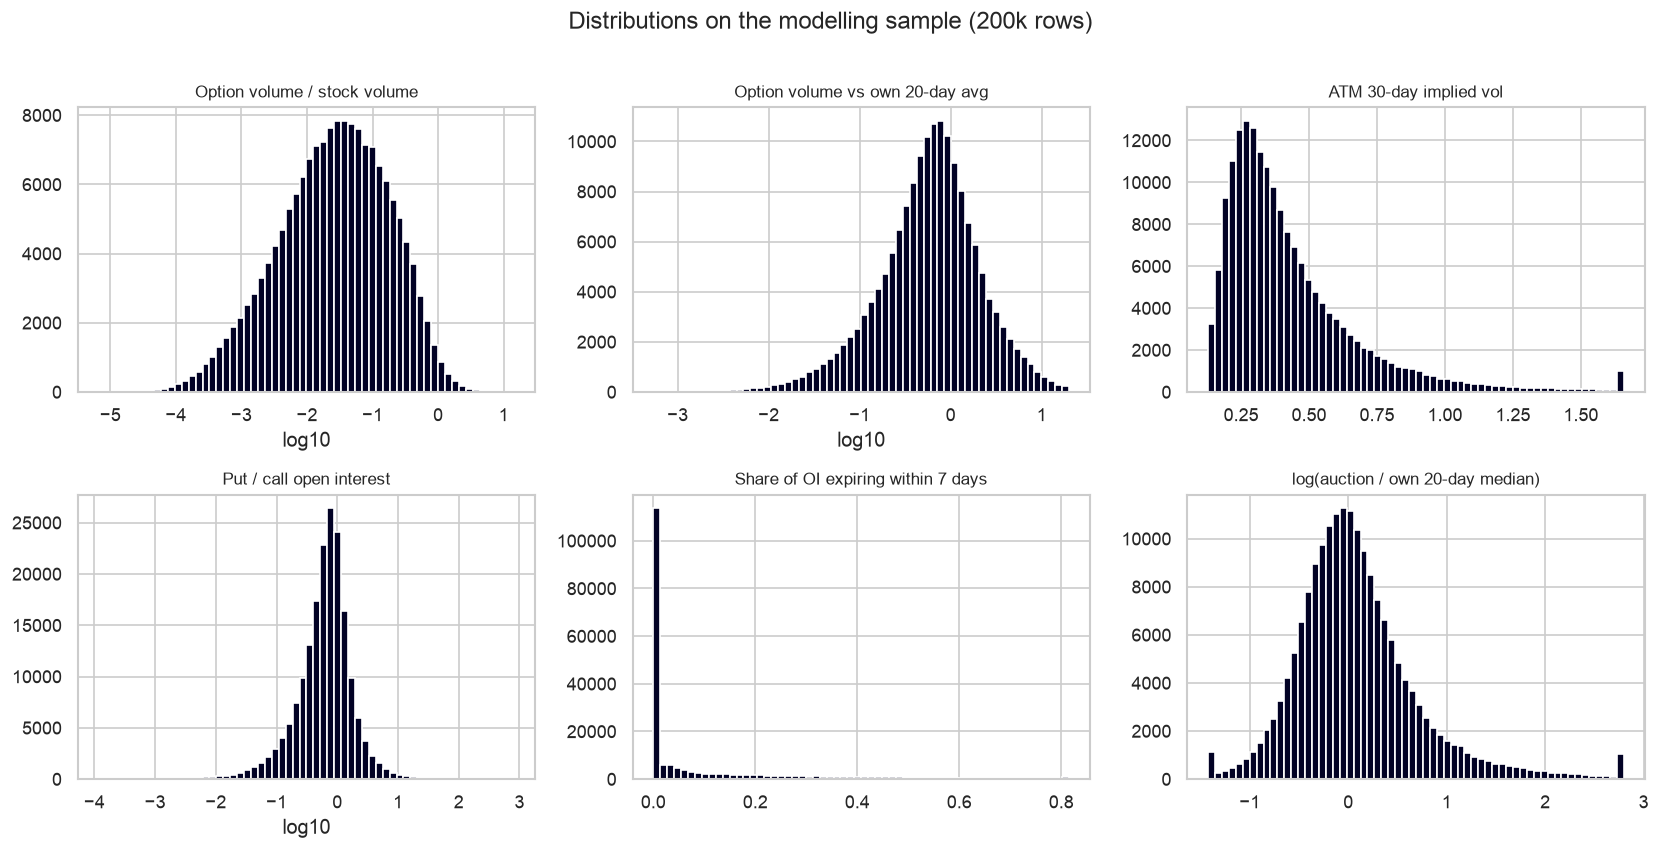

In [18]:
sample = sql(f"""
    SELECT lag1_opt_to_stock_vol, opt_vol_surprise, lag1_iv_atm_30d,
           pc_oi_ratio, oi_exp_7d_share, log_auction_residual
    FROM read_parquet('{JOINT}')
    WHERE {KEEP} AND log_auction_residual IS NOT NULL
    USING SAMPLE 200000 ROWS
""")

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
specs = [("lag1_opt_to_stock_vol", True,  "Option volume / stock volume"),
         ("opt_vol_surprise",      True,  "Option volume vs own 20-day avg"),
         ("lag1_iv_atm_30d",       False, "ATM 30-day implied vol"),
         ("pc_oi_ratio",           True,  "Put / call open interest"),
         ("oi_exp_7d_share",       False, "Share of OI expiring within 7 days"),
         ("log_auction_residual",  False, "log(auction / own 20-day median)")]
for ax, (col, logx, title) in zip(axes.ravel(), specs):
    s = sample[col].replace([np.inf, -np.inf], np.nan).dropna()
    if logx:
        s = s[s > 0]
        ax.hist(np.log10(s), bins=60, color=NAVY)
        ax.set_xlabel("log10")
    else:
        lo, hi = s.quantile([0.005, 0.995])
        ax.hist(s.clip(lo, hi), bins=60, color=NAVY)
    ax.set_title(title, fontsize=10)
fig.suptitle("Distributions on the modelling sample (200k rows)", y=1.01)
fig.tight_layout()
fig.savefig(OUT / "options_distributions.png", bbox_inches="tight")
plt.show()

## 4. Redundancy inside the options block

Seventeen options columns, but they are built from a handful of underlying quantities, so many will
be near-duplicates. Pairs above |0.9| are effectively the same feature and only one needs to survive
into any model.

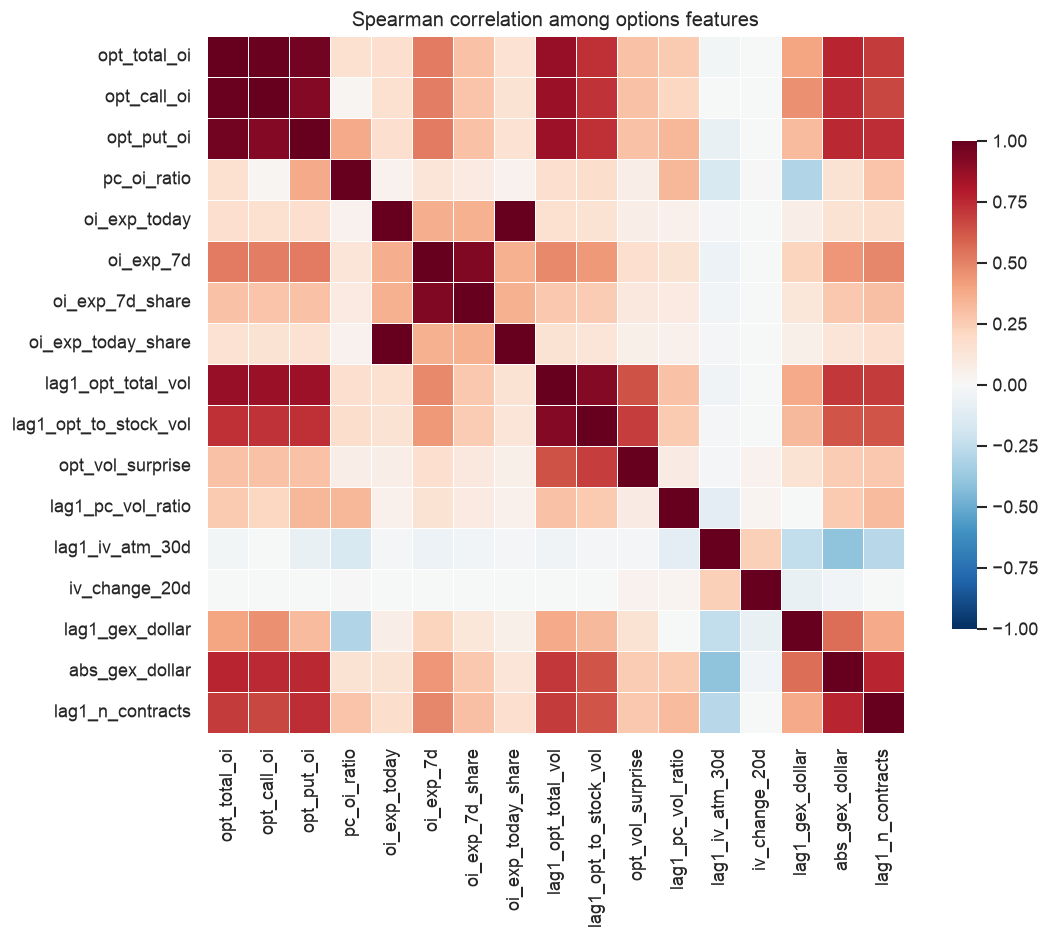

  * Options pairs with |rho| > 0.9: 6


,feature_1,feature_2,spearman
75,oi_exp_today,oi_exp_today_share,0.9981
1,opt_total_oi,opt_call_oi,0.9852
2,opt_total_oi,opt_put_oi,0.9656
91,oi_exp_7d,oi_exp_7d_share,0.9236
145,lag1_opt_total_vol,lag1_opt_to_stock_vol,0.9216
19,opt_call_oi,opt_put_oi,0.9160


In [19]:
corr_sample = sql(f"""
    SELECT {", ".join(OPT_COLS)}
    FROM read_parquet('{JOINT}') WHERE {KEEP}
    USING SAMPLE 200000 ROWS
""").replace([np.inf, -np.inf], np.nan)

cmat = corr_sample.corr(method="spearman")
cmat.to_csv(OUT / "options_internal_correlation.csv")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cmat, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            linewidths=.5, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Spearman correlation among options features")
fig.tight_layout()
fig.savefig(OUT / "options_internal_correlation.png", bbox_inches="tight")
plt.show()

pairs = (cmat.where(np.triu(np.ones(cmat.shape), k=1).astype(bool))
         .stack().reset_index())
pairs.columns = ["feature_1", "feature_2", "spearman"]
high = pairs[pairs["spearman"].abs() > 0.9].sort_values("spearman", key=abs, ascending=False)
high.to_csv(OUT / "options_high_correlation_pairs.csv", index=False)
note("Options pairs with |rho| > 0.9", len(high))
high

# Part B — The target through an options lens

## 5. Optionable versus non-optionable stocks

Before any expiry analysis: are stocks with listed options simply different animals? If their
auctions behave unlike the rest of the universe, that colours everything downstream — and it tells
you which part of the universe this whole layer can ever speak to.

In [20]:
optionable = sql(f"""
SELECT has_options,
       count(*)                       AS stock_days,
       count(DISTINCT permno)         AS stocks,
       median(auction_volume)         AS median_auction,
       median(lag1_auction_share)     AS median_auction_share,
       median(auction_cv20)           AS median_auction_cv20,
       median(size_percentile)        AS median_size_pct,
       median(liquidity_percentile)   AS median_liquidity_pct,
       stddev_samp(log_auction_residual) AS residual_volatility
FROM read_parquet('{JOINT}')
WHERE eligible_target AND median20_auction_volume > 0
GROUP BY 1 ORDER BY 1
""")
optionable.to_csv(OUT / "optionable_vs_not.csv", index=False)
note("Optionable share of eligible stock-days (%)",
     round(100 * optionable.loc[optionable.has_options == 1, "stock_days"].sum()
           / optionable["stock_days"].sum(), 2))
optionable

  * Optionable share of eligible stock-days (%): 95.47


,has_options,stock_days,stocks,median_auction,median_auction_share,median_auction_cv20,median_size_pct,median_liquidity_pct,residual_volatility
0,0,153780,775,"1,784.0000",0.0503,0.8998,0.1197,0.0624,1.0468
1,1,3238205,1949,"58,883.0000",0.0891,0.6659,0.5315,0.5331,0.6581


## 6. Does options activity track the auction's importance?

The auction's share of a stock's daily volume has roughly tripled since 2015. Does options activity
line up with that cross-sectionally — are option-heavy stocks also auction-heavy stocks? If so, much
of what follows may be a liquidity story rather than an options story, which Section 22 tests head-on.

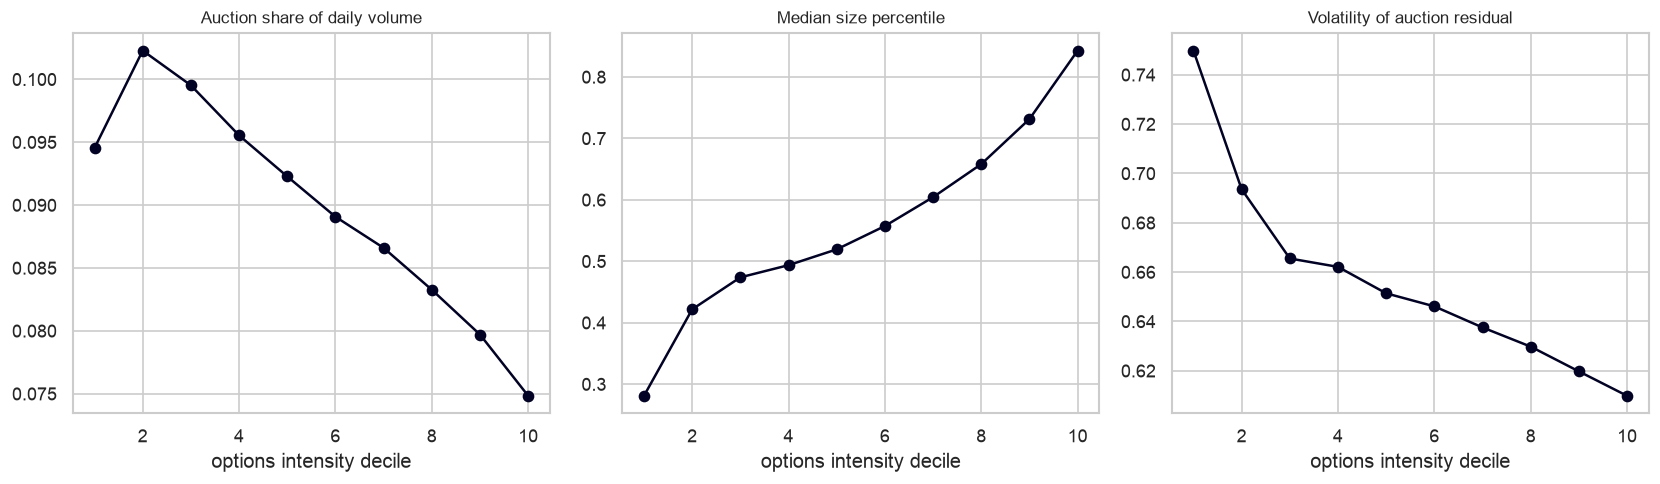

,opt_intensity_decile,n,median_opt_to_stock_vol,median_auction_share,median_size_pct,median_auction_cv20,residual_volatility
0,1,323740,0.0000,0.0945,0.2810,0.7324,0.7498
1,2,323740,0.0005,0.1023,0.4217,0.7065,0.6936
2,3,323740,0.0030,0.0995,0.4738,0.6905,0.6655
3,4,323740,0.0075,0.0955,0.4936,0.6817,0.6621
4,5,323740,0.0149,0.0923,0.5194,0.6743,0.6514
5,6,323740,0.0273,0.0891,0.5573,0.6672,0.6461
6,7,323740,0.0487,0.0866,0.6043,0.6581,0.6375
7,8,323739,0.0888,0.0833,0.6581,0.6453,0.6298
8,9,323739,0.1748,0.0797,0.7314,0.6274,0.6197
9,10,323739,0.4466,0.0748,0.8428,0.6028,0.6098


In [21]:
intensity = sql(f"""
WITH d AS (
    SELECT ntile(10) OVER (ORDER BY lag1_opt_to_stock_vol) AS opt_intensity_decile,
           lag1_opt_to_stock_vol, lag1_auction_share, auction_cv20,
           log_auction_residual, size_percentile
    FROM read_parquet('{JOINT}')
    WHERE {KEEP} AND lag1_opt_to_stock_vol IS NOT NULL
)
SELECT opt_intensity_decile, count(*) AS n,
       median(lag1_opt_to_stock_vol)     AS median_opt_to_stock_vol,
       median(lag1_auction_share)        AS median_auction_share,
       median(size_percentile)           AS median_size_pct,
       median(auction_cv20)              AS median_auction_cv20,
       stddev_samp(log_auction_residual) AS residual_volatility
FROM d GROUP BY 1 ORDER BY 1
""")
intensity.to_csv(OUT / "auction_by_options_intensity.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (col, title) in zip(axes, [
        ("median_auction_share", "Auction share of daily volume"),
        ("median_size_pct",      "Median size percentile"),
        ("residual_volatility",  "Volatility of auction residual")]):
    ax.plot(intensity["opt_intensity_decile"], intensity[col], marker="o", color=NAVY)
    ax.set_xlabel("options intensity decile")
    ax.set_title(title, fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "auction_by_options_intensity.png", bbox_inches="tight")
plt.show()
intensity

# Part C — Expiry

## 7. The expiry calendar

Four kinds of day: nothing expiring, some open interest expiring, a monthly expiry, and a quarterly
expiry — triple witching, when index futures, index options and single-stock options all settle
together. If the mechanism is real, the ordering should be visible before any modelling.

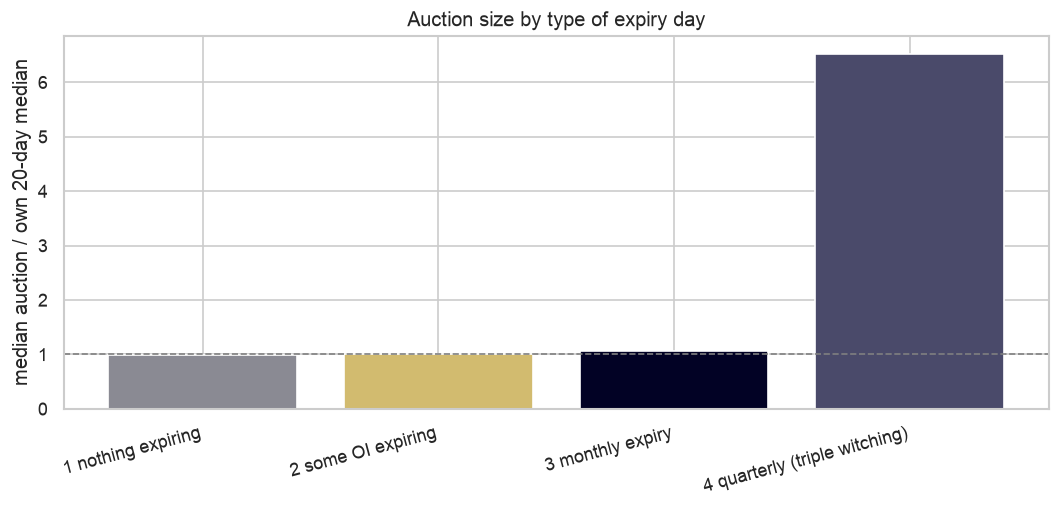

  * Auction lift, busiest expiry type vs none (x): 6.569


,day_type,n,median_auction_vs_normal,mean_log_residual,p90_auction_vs_normal,median_share_expiring
0,1 nothing expiring,2990808,0.9926,0.0536,2.1284,0.0000
1,2 some OI expiring,92572,0.9988,0.0805,2.2227,0.0412
2,3 monthly expiry,103958,1.0541,0.1413,2.3895,0.2297
3,4 quarterly (triple witching),50867,6.5197,1.9751,20.6218,0.2391


In [22]:
calendar = sql(f"""
SELECT
    CASE WHEN quarterly_options_expiry THEN '4 quarterly (triple witching)'
         WHEN monthly_options_expiry   THEN '3 monthly expiry'
         WHEN oi_exp_today > 0         THEN '2 some OI expiring'
         ELSE '1 nothing expiring' END AS day_type,
    count(*) AS n,
    median(auction_vs_normal)              AS median_auction_vs_normal,
    avg(log_auction_residual)              AS mean_log_residual,
    quantile_cont(auction_vs_normal, 0.90) AS p90_auction_vs_normal,
    median(oi_exp_today_share)             AS median_share_expiring
FROM read_parquet('{JOINT}')
WHERE {KEEP}
GROUP BY 1 ORDER BY 1
""")
calendar.to_csv(OUT / "expiry_calendar_contrast.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.bar(calendar["day_type"], calendar["median_auction_vs_normal"],
       color=[GREY, GOLD, NAVY, "#4A4A6A"])
ax.axhline(1.0, color="grey", ls="--", lw=1)
ax.set_ylabel("median auction / own 20-day median")
ax.set_title("Auction size by type of expiry day")
plt.xticks(rotation=15, ha="right")
fig.tight_layout()
fig.savefig(OUT / "expiry_calendar_contrast.png", bbox_inches="tight")
plt.show()

base = float(calendar["median_auction_vs_normal"].iloc[0])
note("Auction lift, busiest expiry type vs none (x)",
     round(float(calendar["median_auction_vs_normal"].max()) / base, 3))
calendar

## 8. Event study around monthly expiry

Does the auction swell only on expiry day, or build and decay around it? Offsets are in trading days
relative to the nearest monthly expiry, measured market-wide. A spike confined to day 0 means a
same-day settlement effect; a ramp means positioning ahead of it, which a forecast made at t−1 could
exploit more easily.

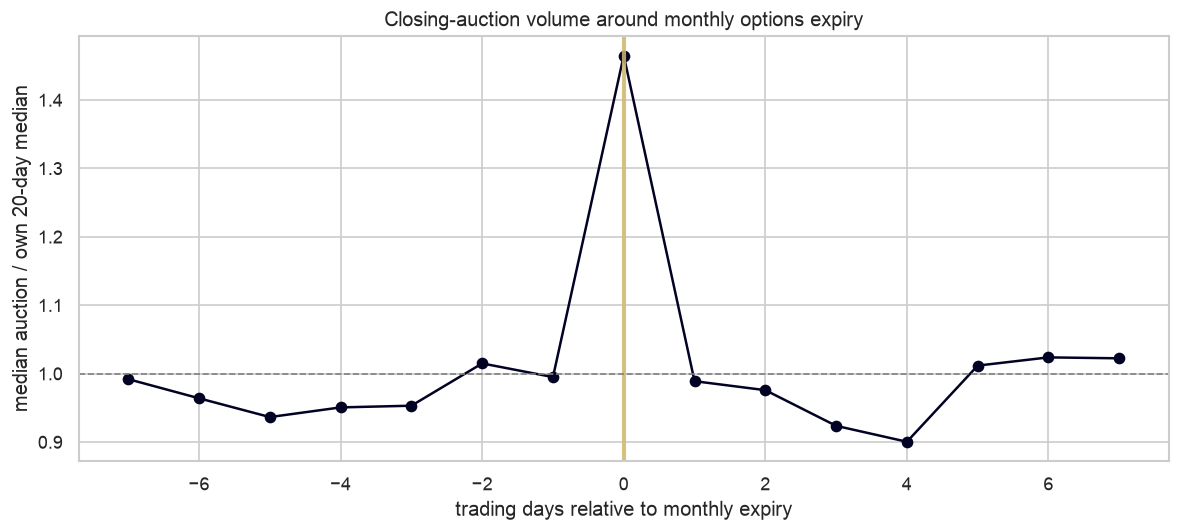

,offset_days,n,median_auction_vs_normal,mean_log_residual
0,-7,154706,0.9919,0.0360
1,-6,154714,0.9639,0.0046
2,-5,154730,0.9365,-0.0161
3,-4,154766,0.9506,-0.0030
4,-3,154744,0.9531,-0.0063
5,-2,154796,1.0149,0.0690
6,-1,154731,0.9949,0.0444
7,0,154825,1.4649,0.7438
8,1,154717,0.9890,0.0474
9,2,154676,0.9758,0.0240


In [23]:
event = sql(f"""
WITH d AS (
    SELECT DISTINCT date, monthly_options_expiry
    FROM read_parquet('{JOINT}') WHERE eligible_target
),
idx AS (
    SELECT date, monthly_options_expiry, row_number() OVER (ORDER BY date) AS t FROM d
),
exp AS (SELECT t FROM idx WHERE monthly_options_expiry),
off AS (
    SELECT i.date,
           i.t - (SELECT e.t FROM exp e ORDER BY abs(e.t - i.t) LIMIT 1) AS offset_days
    FROM idx i
)
SELECT o.offset_days,
       count(*) AS n,
       median(j.auction_vs_normal) AS median_auction_vs_normal,
       avg(j.log_auction_residual) AS mean_log_residual
FROM read_parquet('{JOINT}') j
JOIN off o ON j.date = o.date
WHERE j.eligible_target AND j.has_options = 1 AND j.median20_auction_volume > 0
  AND o.offset_days BETWEEN -7 AND 7
GROUP BY 1 ORDER BY 1
""")
event.to_csv(OUT / "expiry_event_study.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(event["offset_days"], event["median_auction_vs_normal"], marker="o", color=NAVY)
ax.axvline(0, color=GOLD, lw=2.5, alpha=.85)
ax.axhline(1.0, color="grey", ls="--", lw=1)
ax.set_xlabel("trading days relative to monthly expiry")
ax.set_ylabel("median auction / own 20-day median")
ax.set_title("Closing-auction volume around monthly options expiry")
fig.tight_layout()
fig.savefig(OUT / "expiry_event_study.png", bbox_inches="tight")
plt.show()
event

## 9. Anticipation — the seven-day window

`oi_exp_7d` counts open interest expiring within a week, so it is non-zero well before expiry day.
If it predicts the auction on *ordinary* days — days when nothing expires today — then the signal is
about positioning ahead of expiry rather than settlement itself, and it would apply far more often
than the twelve monthly expiry days a year.

In [24]:
anticipation = sql(f"""
WITH d AS (
    SELECT ntile(10) OVER (ORDER BY oi_exp_7d_share) AS decile,
           oi_exp_7d_share, auction_vs_normal
    FROM read_parquet('{JOINT}')
    WHERE {KEEP} AND oi_exp_today = 0 AND oi_exp_7d > 0 AND opt_total_oi > 0
)
SELECT decile, count(*) AS n,
       median(oi_exp_7d_share)   AS median_share_expiring_7d,
       median(auction_vs_normal) AS median_auction_vs_normal
FROM d GROUP BY 1 ORDER BY 1
""")
anticipation.to_csv(OUT / "expiry_anticipation_deciles.csv", index=False)
spread = float(anticipation["median_auction_vs_normal"].iloc[-1]
               - anticipation["median_auction_vs_normal"].iloc[0])
note("Anticipation spread on non-expiry days (D10-D1)", round(spread, 4))
anticipation

  * Anticipation spread on non-expiry days (D10-D1): 0.0087


,decile,n,median_share_expiring_7d,median_auction_vs_normal
0,1,106748,0.0134,0.9692
1,2,106748,0.0290,0.9698
2,3,106748,0.0459,0.9746
3,4,106748,0.0714,0.9837
4,5,106748,0.1155,0.9845
5,6,106748,0.1735,0.9812
6,7,106748,0.2443,0.9821
7,8,106748,0.3358,0.9802
8,9,106748,0.4590,0.9743
9,10,106748,0.6519,0.9779


## 10. Dose-response — does *more* expiring mean a bigger auction?

`oi_exp_today` is zero on most days, so a raw decile split would only re-separate expiry days from
ordinary ones. Restrict to days where something is expiring and split on the **share** of the stock's
open interest rolling off, which is comparable across large and small names.

A rising curve is the real evidence for the mechanism. A flat one means expiry is a binary event and
the magnitude adds nothing.

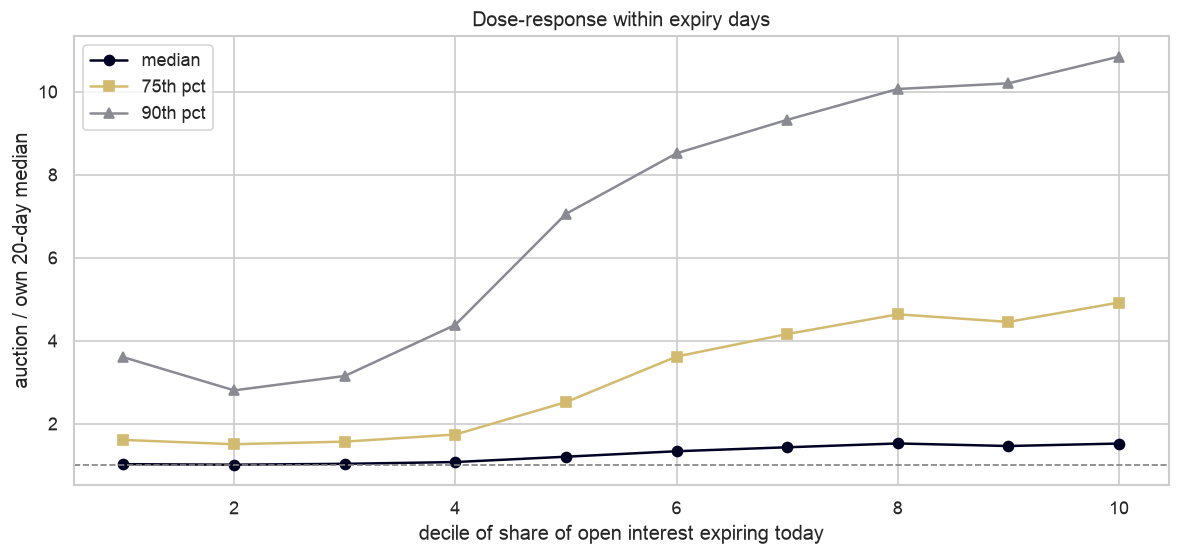

  * Dose-response spread (D10-D1): 0.4973


,decile,n,median_share_expiring,median_auction_vs_normal,p75,p90
0,1,24358,0.0139,1.0238,1.6080,3.6012
1,2,24358,0.0291,1.0117,1.5047,2.8023
2,3,24358,0.0442,1.0324,1.5669,3.1491
3,4,24358,0.0646,1.0751,1.7389,4.3811
4,5,24358,0.0983,1.2038,2.5190,7.0548
5,6,24358,0.1482,1.3356,3.6169,8.5145
6,7,24358,0.2115,1.4310,4.1597,9.3209
7,8,24358,0.2940,1.5231,4.6347,10.0648
8,9,24358,0.4117,1.4616,4.4522,10.2008
9,10,24357,0.6057,1.5211,4.9186,10.8448


In [25]:
deciles = sql(f"""
WITH d AS (
    SELECT auction_vs_normal, oi_exp_today_share,
           ntile(10) OVER (ORDER BY oi_exp_today_share) AS decile
    FROM read_parquet('{JOINT}')
    WHERE {KEEP} AND oi_exp_today > 0 AND opt_total_oi > 0
)
SELECT decile, count(*) AS n,
       median(oi_exp_today_share)             AS median_share_expiring,
       median(auction_vs_normal)              AS median_auction_vs_normal,
       quantile_cont(auction_vs_normal, 0.75) AS p75,
       quantile_cont(auction_vs_normal, 0.90) AS p90
FROM d GROUP BY 1 ORDER BY 1
""")
deciles.to_csv(OUT / "expiry_dose_response.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(deciles["decile"], deciles["median_auction_vs_normal"], marker="o", color=NAVY, label="median")
ax.plot(deciles["decile"], deciles["p75"], marker="s", color=GOLD, label="75th pct")
ax.plot(deciles["decile"], deciles["p90"], marker="^", color=GREY, label="90th pct")
ax.axhline(1.0, color="grey", ls="--", lw=1)
ax.set_xlabel("decile of share of open interest expiring today")
ax.set_ylabel("auction / own 20-day median")
ax.set_title("Dose-response within expiry days")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "expiry_dose_response.png", bbox_inches="tight")
plt.show()

note("Dose-response spread (D10-D1)",
     round(float(deciles["median_auction_vs_normal"].iloc[-1]
                 - deciles["median_auction_vs_normal"].iloc[0]), 4))
deciles

## 11. Beyond the flag the panel already has

The decisive test. The panel can already switch on `monthly_options_expiry`. If the dose-response
vanishes once that flag is held fixed, the options layer is redundant. If a spread survives *within*
`monthly_options_expiry = 1`, the magnitude carries information the flag cannot express — and that
is the case for integrating it.

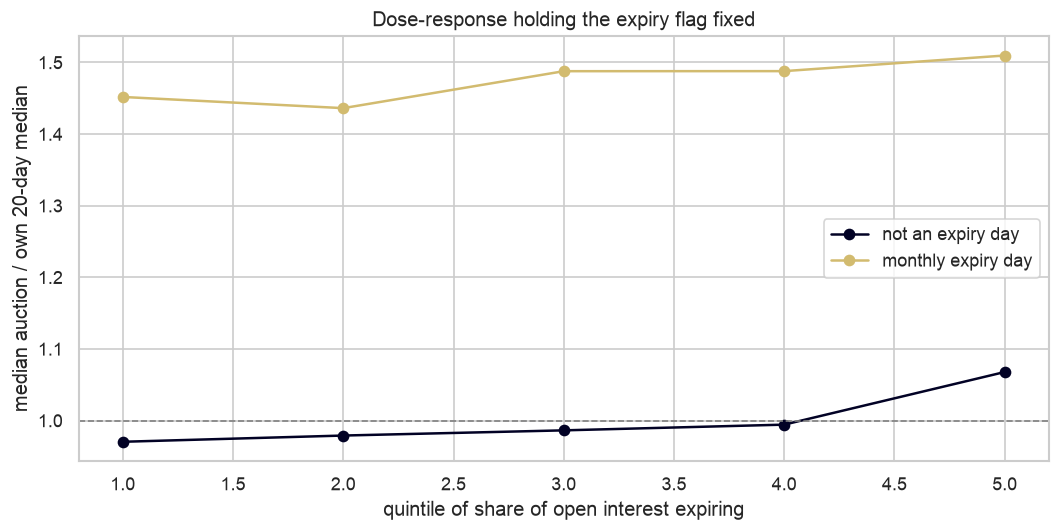

  * Spread within expiry days (Q5-Q1): 0.0579


,monthly_options_expiry,quintile,n,median_share_expiring,median_auction_vs_normal
0,False,1,18515,0.0143,0.9703
1,False,2,18515,0.0280,0.9790
2,False,3,18514,0.0412,0.9863
3,False,4,18514,0.0596,0.9942
4,False,5,18514,0.1027,1.0677
5,True,1,30202,0.0589,1.4518
6,True,2,30202,0.1488,1.4362
7,True,3,30201,0.2389,1.4878
8,True,4,30201,0.3640,1.4879
9,True,5,30201,0.5726,1.5097


In [26]:
within_flag = sql(f"""
WITH d AS (
    SELECT monthly_options_expiry, auction_vs_normal, oi_exp_today_share,
           ntile(5) OVER (PARTITION BY monthly_options_expiry ORDER BY oi_exp_today_share) AS quintile
    FROM read_parquet('{JOINT}')
    WHERE {KEEP} AND oi_exp_today > 0 AND opt_total_oi > 0
)
SELECT monthly_options_expiry, quintile, count(*) AS n,
       median(oi_exp_today_share) AS median_share_expiring,
       median(auction_vs_normal)  AS median_auction_vs_normal
FROM d GROUP BY 1, 2 ORDER BY 1, 2
""")
within_flag.to_csv(OUT / "effect_within_expiry_flag.csv", index=False)

pivot = within_flag.pivot(index="quintile", columns="monthly_options_expiry",
                          values="median_auction_vs_normal")
fig, ax = plt.subplots(figsize=(9, 4.6))
labels = {False: "not an expiry day", True: "monthly expiry day"}
for col, colour in zip(pivot.columns, [NAVY, GOLD]):
    ax.plot(pivot.index, pivot[col], marker="o", color=colour,
            label=labels.get(col, str(col)))
ax.axhline(1.0, color="grey", ls="--", lw=1)
ax.set_xlabel("quintile of share of open interest expiring")
ax.set_ylabel("median auction / own 20-day median")
ax.set_title("Dose-response holding the expiry flag fixed")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "effect_within_expiry_flag.png", bbox_inches="tight")
plt.show()

on_flag = within_flag[within_flag["monthly_options_expiry"] == True]
if len(on_flag) >= 2:
    note("Spread within expiry days (Q5-Q1)",
         round(float(on_flag["median_auction_vs_normal"].iloc[-1]
                     - on_flag["median_auction_vs_normal"].iloc[0]), 4))
within_flag

## 12. Expiry against month-end

Month-end is the other big auction day — index rebalancing and benchmark-tracking flows both settle
at the close, and the panel already has five features for it. When an expiry lands in a month-end
window, do the two effects compound, or does one simply absorb the other?

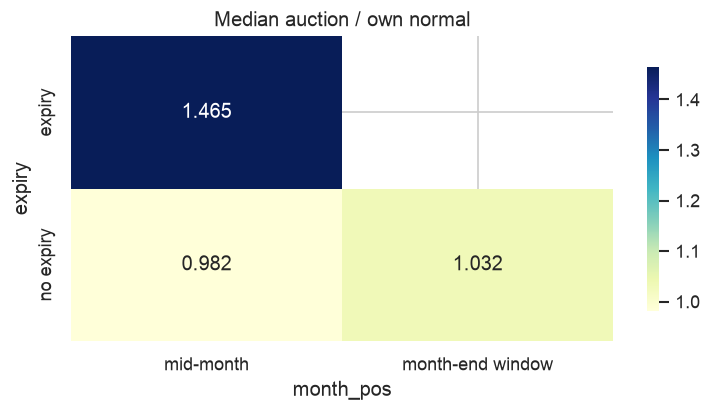

month_pos,mid-month,month-end window
expiry,,
expiry,1.4649,NaN
no expiry,0.9821,1.0319


,expiry,month_pos,n,median_auction_vs_normal
0,expiry,mid-month,154825,1.4649
1,no expiry,mid-month,2309810,0.9821
2,no expiry,month-end window,773570,1.0319


In [27]:
interaction = sql(f"""
SELECT
    CASE WHEN monthly_options_expiry THEN 'expiry' ELSE 'no expiry' END AS expiry,
    CASE WHEN is_last_5_trading_days_month THEN 'month-end window' ELSE 'mid-month' END AS month_pos,
    count(*) AS n,
    median(auction_vs_normal) AS median_auction_vs_normal
FROM read_parquet('{JOINT}')
WHERE {KEEP}
GROUP BY 1, 2 ORDER BY 1, 2
""")
interaction.to_csv(OUT / "expiry_x_month_end.csv", index=False)

grid = interaction.pivot(index="expiry", columns="month_pos", values="median_auction_vs_normal")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.heatmap(grid, annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Median auction / own normal")
fig.tight_layout()
fig.savefig(OUT / "expiry_x_month_end.png", bbox_inches="tight")
plt.show()
display(grid)
interaction

# Part D — Channels other than expiry

## 13. Option volume: level versus surprise

Big stocks always have big option volume, so the *level* mostly restates size. `opt_vol_surprise`
divides yesterday's option volume by the stock's own 20-day average, which strips that out. If the
surprise predicts the auction and the level does not, the signal is about unusual activity rather
than about which stock it is.

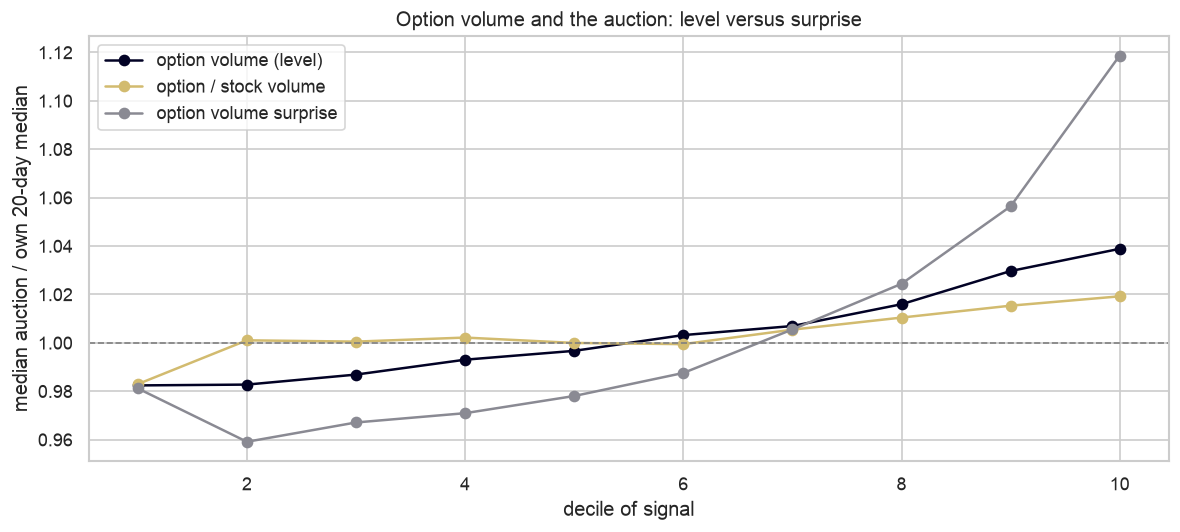

signal,option / stock volume,option volume (level),option volume surprise
decile,,,
1,0.9830,0.9824,0.9812
2,1.0010,0.9827,0.9591
3,1.0005,0.9869,0.9671
4,1.0022,0.9930,0.9709
5,1.0000,0.9967,0.9780
6,0.9995,1.0032,0.9876
7,1.0054,1.0069,1.0055
8,1.0104,1.0160,1.0244
9,1.0154,1.0297,1.0564


In [28]:
def decile_curve(signal, extra_filter="TRUE", bins=10, label=None):
    """Median auction residual across deciles of a signal. Returns a tidy frame."""
    df = sql(f"""
        WITH d AS (
            SELECT ntile({bins}) OVER (ORDER BY {signal}) AS decile,
                   {signal} AS signal_value, auction_vs_normal
            FROM read_parquet('{JOINT}')
            WHERE {KEEP} AND {signal} IS NOT NULL AND isfinite({signal}) AND {extra_filter}
        )
        SELECT decile, count(*) AS n,
               median(signal_value)      AS median_signal,
               median(auction_vs_normal) AS median_auction_vs_normal
        FROM d GROUP BY 1 ORDER BY 1
    """)
    df["signal"] = label or signal
    return df

vol_curves = pd.concat([
    decile_curve("lag1_opt_total_vol",    label="option volume (level)"),
    decile_curve("lag1_opt_to_stock_vol", label="option / stock volume"),
    decile_curve("opt_vol_surprise",      label="option volume surprise"),
])
vol_curves.to_csv(OUT / "channel_option_volume.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.6))
for (name, grp), colour in zip(vol_curves.groupby("signal", sort=False), [NAVY, GOLD, GREY]):
    ax.plot(grp["decile"], grp["median_auction_vs_normal"], marker="o", color=colour, label=name)
ax.axhline(1.0, color="grey", ls="--", lw=1)
ax.set_xlabel("decile of signal")
ax.set_ylabel("median auction / own 20-day median")
ax.set_title("Option volume and the auction: level versus surprise")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "channel_option_volume.png", bbox_inches="tight")
plt.show()
vol_curves.pivot(index="decile", columns="signal", values="median_auction_vs_normal")

## 14. Implied volatility — level and change

High implied vol means the market expects movement, which usually comes with heavier trading. The
level may again just rank stocks by riskiness, so `iv_change_20d` is the more interesting column:
a stock whose implied vol has jumped this month is in a changed regime.

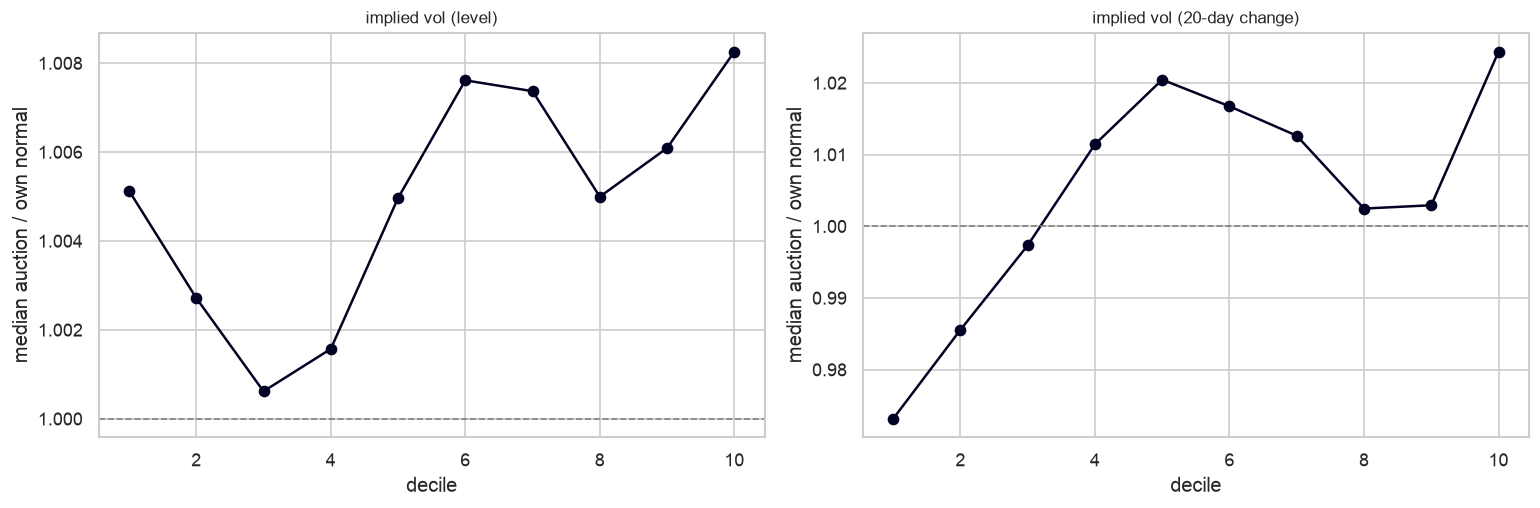

signal,implied vol (20-day change),implied vol (level)
decile,,
1,0.9731,1.0051
2,0.9856,1.0027
3,0.9973,1.0006
4,1.0114,1.0016
5,1.0204,1.0050
6,1.0167,1.0076
7,1.0126,1.0074
8,1.0025,1.0050
9,1.0029,1.0061


In [29]:
iv_curves = pd.concat([
    decile_curve("lag1_iv_atm_30d", label="implied vol (level)"),
    decile_curve("iv_change_20d",   label="implied vol (20-day change)"),
])
iv_curves.to_csv(OUT / "channel_implied_vol.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, (name, grp) in zip(axes, iv_curves.groupby("signal", sort=False)):
    ax.plot(grp["decile"], grp["median_auction_vs_normal"], marker="o", color=NAVY)
    ax.axhline(1.0, color="grey", ls="--", lw=1)
    ax.set_xlabel("decile")
    ax.set_ylabel("median auction / own normal")
    ax.set_title(name, fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "channel_implied_vol.png", bbox_inches="tight")
plt.show()
iv_curves.pivot(index="decile", columns="signal", values="median_auction_vs_normal")

## 15. Dealer gamma — signed and absolute

`gex_dollar` estimates how much dealers must trade to stay hedged per 1% move, assuming they are long
calls and short puts. The sign depends entirely on that convention, so the **absolute** value is the
more defensible quantity: large gamma either way means large hedging flow, and a lot of hedging is
done at the close. Both are shown; if only `abs_gex_dollar` works, the mechanism is magnitude rather
than direction.

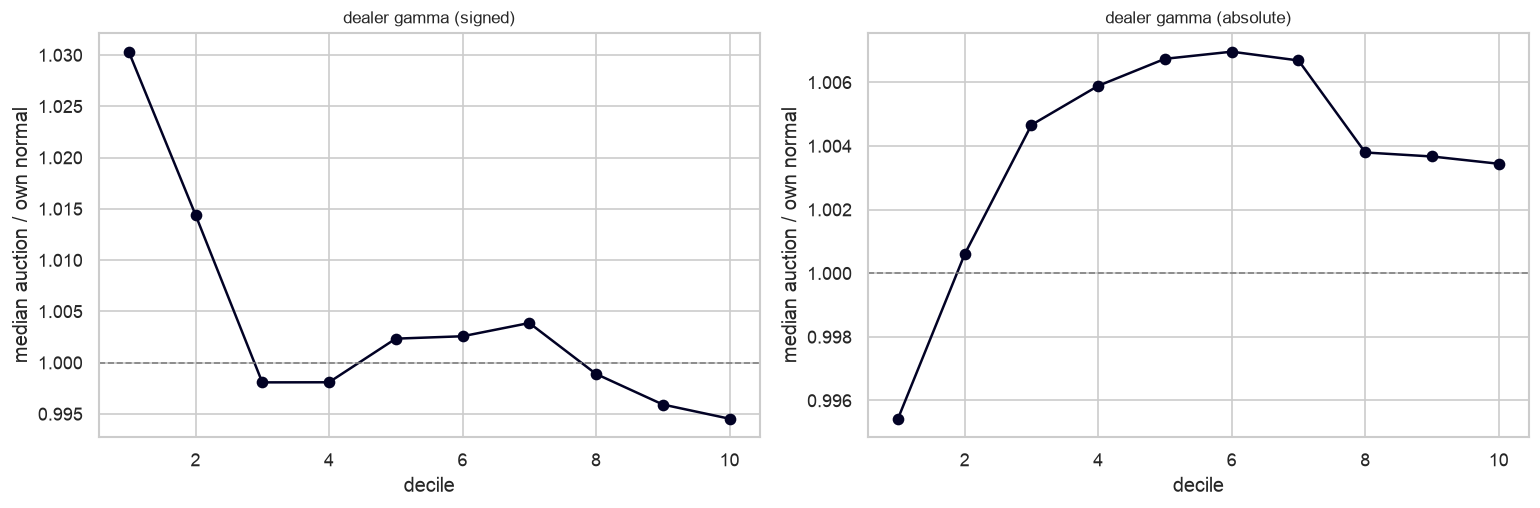

signal,dealer gamma (absolute),dealer gamma (signed)
decile,,
1,0.9954,1.0303
2,1.0006,1.0144
3,1.0047,0.9981
4,1.0059,0.9981
5,1.0067,1.0023
6,1.0070,1.0026
7,1.0067,1.0039
8,1.0038,0.9989
9,1.0037,0.9959


In [30]:
gex_curves = pd.concat([
    decile_curve("lag1_gex_dollar", label="dealer gamma (signed)"),
    decile_curve("abs_gex_dollar",  label="dealer gamma (absolute)"),
])
gex_curves.to_csv(OUT / "channel_dealer_gamma.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, (name, grp) in zip(axes, gex_curves.groupby("signal", sort=False)):
    ax.plot(grp["decile"], grp["median_auction_vs_normal"], marker="o", color=NAVY)
    ax.axhline(1.0, color="grey", ls="--", lw=1)
    ax.set_xlabel("decile")
    ax.set_ylabel("median auction / own normal")
    ax.set_title(name, fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "channel_dealer_gamma.png", bbox_inches="tight")
plt.show()
gex_curves.pivot(index="decile", columns="signal", values="median_auction_vs_normal")

## 16. The put/call balance

Auction *volume* is unsigned, so a directional skew should matter less than the sheer amount of
positioning. Both the volume ratio and the open-interest ratio are shown; a U-shape would mean
lopsidedness in either direction brings flow, a flat line that direction is irrelevant.

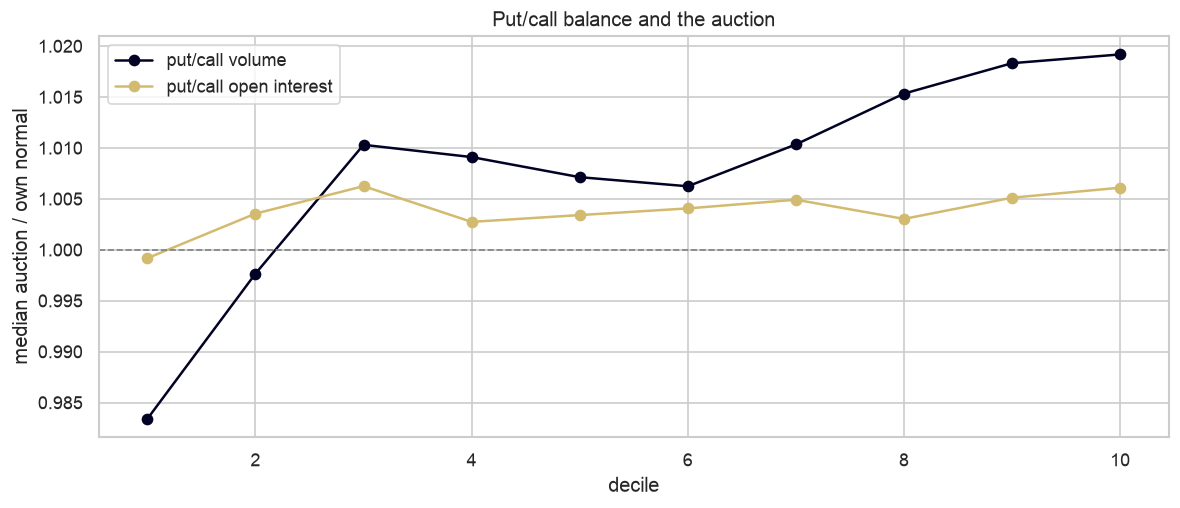

signal,put/call open interest,put/call volume
decile,,
1,0.9992,0.9834
2,1.0035,0.9976
3,1.0062,1.0103
4,1.0027,1.0091
5,1.0034,1.0071
6,1.0041,1.0062
7,1.0049,1.0103
8,1.0030,1.0153
9,1.0051,1.0183


In [31]:
pc_curves = pd.concat([
    decile_curve("lag1_pc_vol_ratio", label="put/call volume"),
    decile_curve("pc_oi_ratio",       label="put/call open interest"),
])
pc_curves.to_csv(OUT / "channel_put_call.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.4))
for (name, grp), colour in zip(pc_curves.groupby("signal", sort=False), [NAVY, GOLD]):
    ax.plot(grp["decile"], grp["median_auction_vs_normal"], marker="o", color=colour, label=name)
ax.axhline(1.0, color="grey", ls="--", lw=1)
ax.set_xlabel("decile")
ax.set_ylabel("median auction / own normal")
ax.set_title("Put/call balance and the auction")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "channel_put_call.png", bbox_inches="tight")
plt.show()
pc_curves.pivot(index="decile", columns="signal", values="median_auction_vs_normal")

# Part E — Who this applies to

## 17. Size, liquidity and options intensity

The global model is weakest on small illiquid names — CATO-type stocks back-test at 0.50 WAPE with
−29% bias against 0.30 for JPM. Options coverage is thinnest in exactly that segment, so any benefit
may land where it is least needed. "Lift" is the median auction residual on expiry days minus the
same on ordinary days.

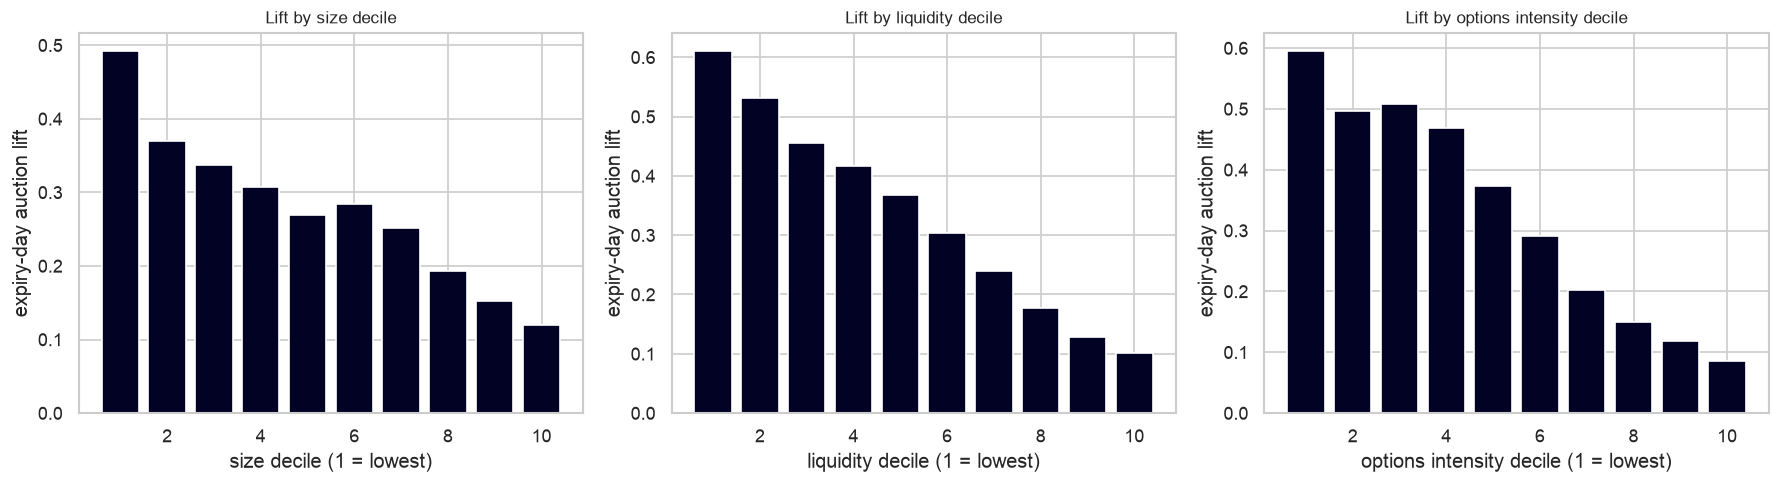

,bucket,n,has_options_pct,expiring,not_expiring,lift
0,1,299532,77.7159,1.4569,0.9653,0.4916
1,2,320412,88.5304,1.3633,0.9939,0.3694
2,3,343090,94.5070,1.3354,0.9976,0.3378
3,4,345354,96.4787,1.3056,0.9982,0.3074
4,5,347142,98.0267,1.2676,0.9984,0.2692
5,6,347426,98.9825,1.2803,0.9966,0.2837
6,7,347191,99.5458,1.2459,0.9938,0.2521
7,8,347852,99.0154,1.1876,0.9952,0.1925
8,9,347641,99.5829,1.1439,0.9911,0.1529
9,10,346345,99.2961,1.1045,0.9852,0.1194


,bucket,n,expiring,not_expiring,lift
0,1,323740,1.5589,0.9644,0.5945
1,2,323740,1.4957,0.9986,0.4971
2,3,323740,1.4985,0.9900,0.5086
3,4,323740,1.4600,0.9919,0.4681
4,5,323740,1.3629,0.9895,0.3733
5,6,323740,1.2801,0.9887,0.2914
6,7,323740,1.1967,0.9949,0.2019
7,8,323739,1.1492,0.9998,0.1494
8,9,323739,1.1216,1.0028,0.1189
9,10,323739,1.0928,1.0065,0.0863


In [32]:
def lift_by(group_col, filter_sql=None):
    df = sql(f"""
        SELECT {group_col} AS bucket, count(*) AS n,
               100.0 * avg(CASE WHEN has_options = 1 THEN 1.0 ELSE 0.0 END) AS has_options_pct,
               median(CASE WHEN oi_exp_today > 0 THEN auction_vs_normal END) AS expiring,
               median(CASE WHEN oi_exp_today = 0 THEN auction_vs_normal END) AS not_expiring
        FROM read_parquet('{JOINT}')
        WHERE eligible_target AND median20_auction_volume > 0
          AND {group_col} IS NOT NULL {f"AND {filter_sql}" if filter_sql else ""}
        GROUP BY 1 ORDER BY 1
    """)
    df["lift"] = df["expiring"] - df["not_expiring"]
    df["dimension"] = group_col
    return df

by_size = lift_by("size_decile")
by_liq = lift_by("liquidity_decile")
by_size.to_csv(OUT / "lift_by_size_decile.csv", index=False)
by_liq.to_csv(OUT / "lift_by_liquidity_decile.csv", index=False)

opt_intensity = sql(f"""
WITH d AS (
    SELECT ntile(10) OVER (ORDER BY lag1_opt_to_stock_vol) AS bucket,
           oi_exp_today, auction_vs_normal
    FROM read_parquet('{JOINT}')
    WHERE {KEEP} AND lag1_opt_to_stock_vol IS NOT NULL
)
SELECT bucket, count(*) AS n,
       median(CASE WHEN oi_exp_today > 0 THEN auction_vs_normal END) AS expiring,
       median(CASE WHEN oi_exp_today = 0 THEN auction_vs_normal END) AS not_expiring
FROM d GROUP BY 1 ORDER BY 1
""")
opt_intensity["lift"] = opt_intensity["expiring"] - opt_intensity["not_expiring"]
opt_intensity.to_csv(OUT / "lift_by_options_intensity.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (df, title) in zip(axes, [(by_size, "size decile"),
                                  (by_liq, "liquidity decile"),
                                  (opt_intensity, "options intensity decile")]):
    ax.bar(df["bucket"], df["lift"], color=NAVY)
    ax.axhline(0, color="grey", lw=1)
    ax.set_xlabel(f"{title} (1 = lowest)")
    ax.set_ylabel("expiry-day auction lift")
    ax.set_title(f"Lift by {title}", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "lift_by_size_liquidity_intensity.png", bbox_inches="tight")
plt.show()

display(by_size[["bucket", "n", "has_options_pct", "expiring", "not_expiring", "lift"]])
opt_intensity

## 18. Sector

FF12 sectors. Differences here are usually about index membership and how heavily a sector is used
for hedging rather than anything intrinsic to the businesses.

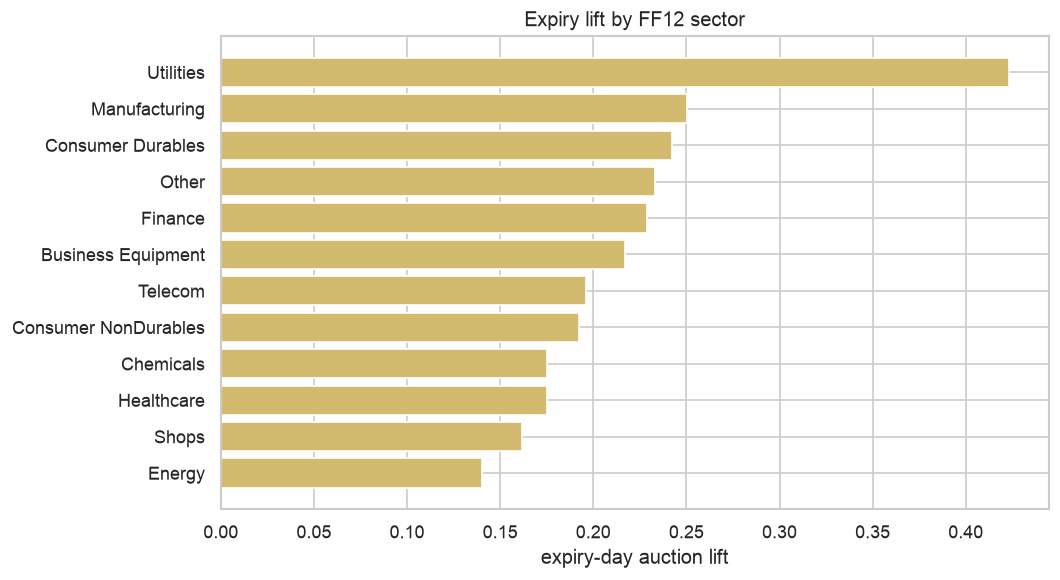

,bucket,n,expiring,not_expiring,lift
11,Utilities,169707,1.4152,0.9918,0.4234
7,Manufacturing,412562,1.2421,0.9919,0.2501
2,Consumer Durables,101609,1.2333,0.9909,0.2424
8,Other,519326,1.2261,0.9928,0.2332
5,Finance,554532,1.2209,0.9923,0.2287
0,Business Equipment,355323,1.2126,0.9955,0.2171
10,Telecom,66279,1.1883,0.9922,0.1961
3,Consumer NonDurables,165638,1.1854,0.9929,0.1924
1,Chemicals,139599,1.1680,0.9926,0.1754
6,Healthcare,163701,1.1686,0.9933,0.1753


In [33]:
by_sector = lift_by("ff12_name", filter_sql="has_options = 1")
by_sector = by_sector.sort_values("lift", ascending=False)
by_sector.to_csv(OUT / "lift_by_sector.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(by_sector["bucket"], by_sector["lift"], color=GOLD)
ax.axvline(0, color="grey", lw=1)
ax.set_xlabel("expiry-day auction lift")
ax.set_title("Expiry lift by FF12 sector")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(OUT / "lift_by_sector.png", bbox_inches="tight")
plt.show()
by_sector[["bucket", "n", "expiring", "not_expiring", "lift"]]

## 19. Case studies

Aggregates hide mechanics. Six stocks spanning the size and liquidity range — the same names
notebooks 12 and 13 track — plotted as auction residual against time, with monthly expiries marked.
This is where you see whether the effect is a reliable monthly pulse or an occasional coincidence.

,ticker,n,has_options_pct,expiring,not_expiring,lift
3,DIN,2679,99.9627,1.4962,0.9965,0.4996
5,CATO,2679,100.0000,1.4421,0.9831,0.4590
4,FBP,2679,100.0000,1.4337,0.9989,0.4347
0,BLK,2679,100.0000,1.0985,0.9754,0.1231
2,JPM,2679,100.0000,1.0843,0.9769,0.1074
1,AEO,2679,100.0000,1.0272,1.0081,0.0192


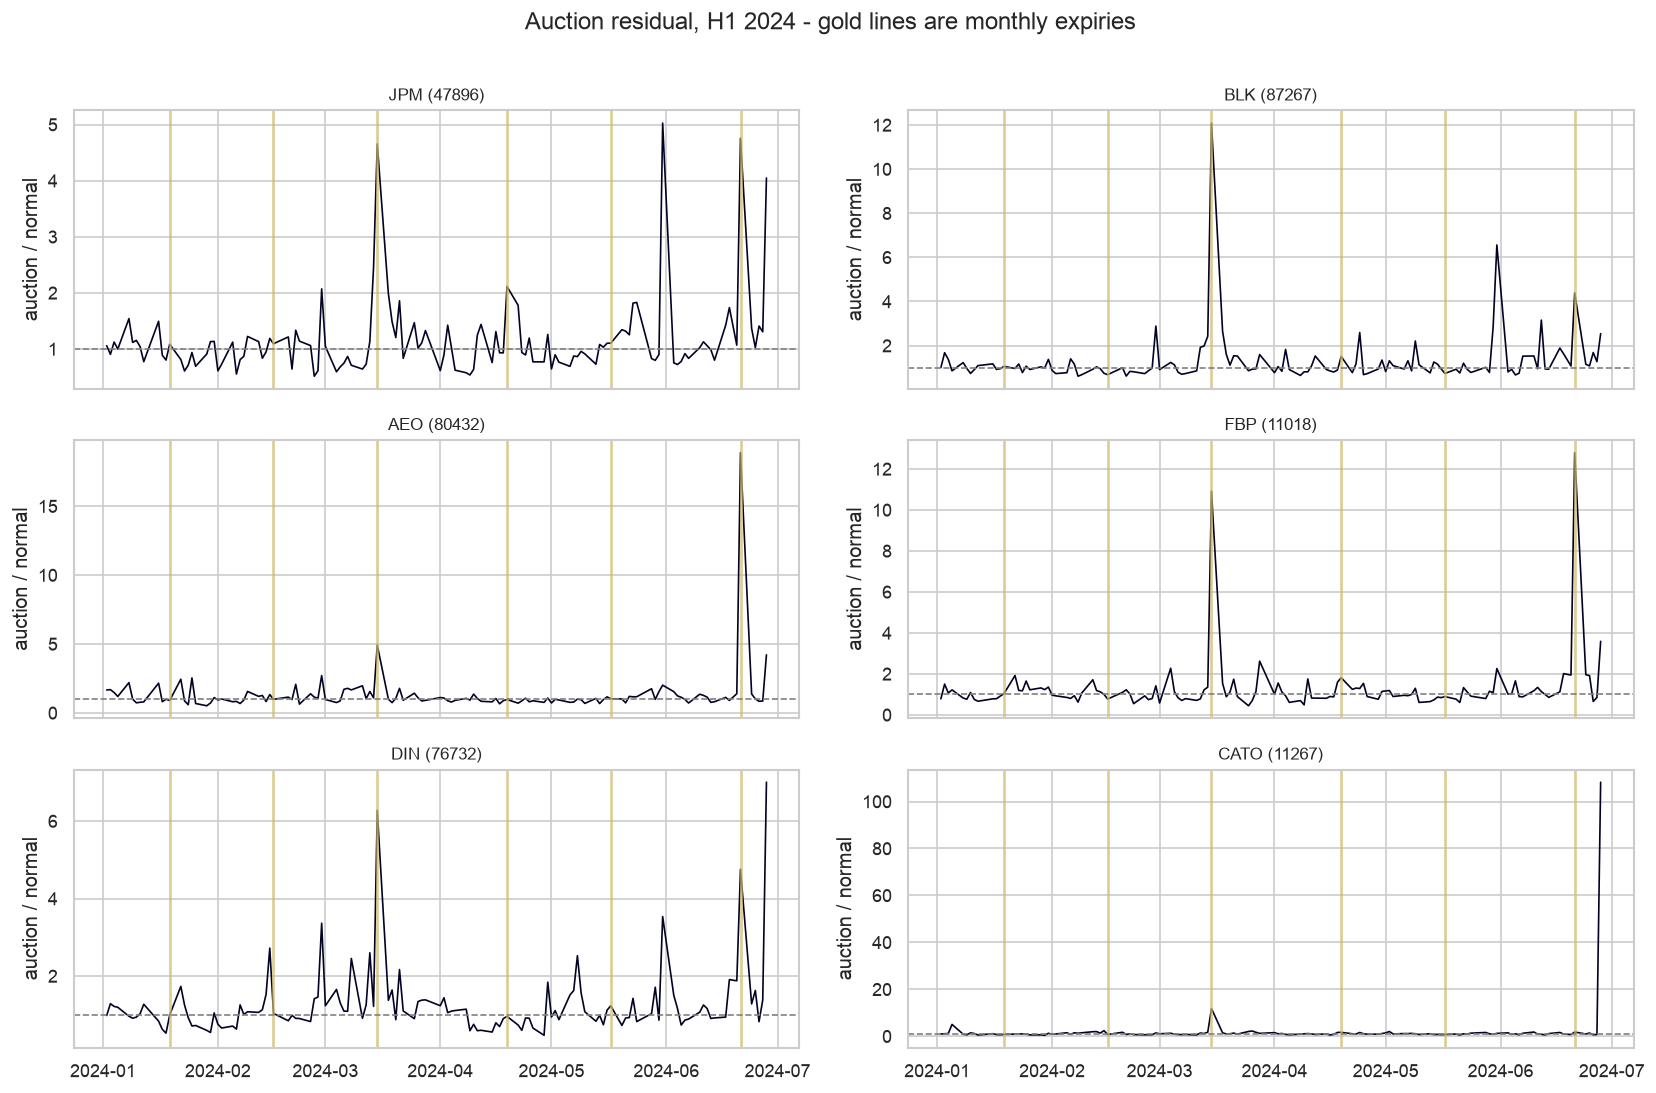

In [34]:
CASES = {47896: "JPM", 87267: "BLK", 80432: "AEO", 11018: "FBP", 76732: "DIN", 11267: "CATO"}
case_list = ", ".join(str(p) for p in CASES)

case_stats = sql(f"""
SELECT permno, count(*) AS n,
       100.0 * avg(CASE WHEN has_options = 1 THEN 1.0 ELSE 0.0 END) AS has_options_pct,
       median(CASE WHEN oi_exp_today > 0 THEN auction_vs_normal END) AS expiring,
       median(CASE WHEN oi_exp_today = 0 THEN auction_vs_normal END) AS not_expiring,
       median(oi_exp_today_share) AS median_share_expiring
FROM read_parquet('{JOINT}')
WHERE eligible_target AND median20_auction_volume > 0 AND permno IN ({case_list})
GROUP BY 1
""")
case_stats["ticker"] = case_stats["permno"].map(CASES)
case_stats["lift"] = case_stats["expiring"] - case_stats["not_expiring"]
case_stats = case_stats.sort_values("lift", ascending=False)
case_stats.to_csv(OUT / "case_study_summary.csv", index=False)
display(case_stats[["ticker", "n", "has_options_pct", "expiring", "not_expiring", "lift"]])

series = sql(f"""
SELECT permno, date, auction_vs_normal, monthly_options_expiry, oi_exp_today_share
FROM read_parquet('{JOINT}')
WHERE {KEEP} AND permno IN ({case_list})
  AND date >= DATE '2024-01-01' AND date < DATE '2024-07-01'
ORDER BY permno, date
""")

fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)
for ax, (permno, tkr) in zip(axes.ravel(), CASES.items()):
    g = series[series["permno"] == permno]
    ax.plot(g["date"], g["auction_vs_normal"], color=NAVY, lw=1)
    for d in g.loc[g["monthly_options_expiry"] == True, "date"]:
        ax.axvline(d, color=GOLD, lw=1.6, alpha=.75)
    ax.axhline(1.0, color="grey", ls="--", lw=1)
    ax.set_title(f"{tkr} ({permno})", fontsize=10)
    ax.set_ylabel("auction / normal")
fig.suptitle("Auction residual, H1 2024 - gold lines are monthly expiries", y=1.01)
fig.tight_layout()
fig.savefig(OUT / "case_study_series.png", bbox_inches="tight")
plt.show()

# Part F — Has any of this been stable?

## 20. The effect over time

Options markets changed enormously over this sample: retail participation surged after 2020 and
short-dated contracts came to dominate volume. An effect that only exists in the recent half, or only
in the early half, is a much weaker basis for a model than one that persists. Shown per year, on the
same definition throughout.

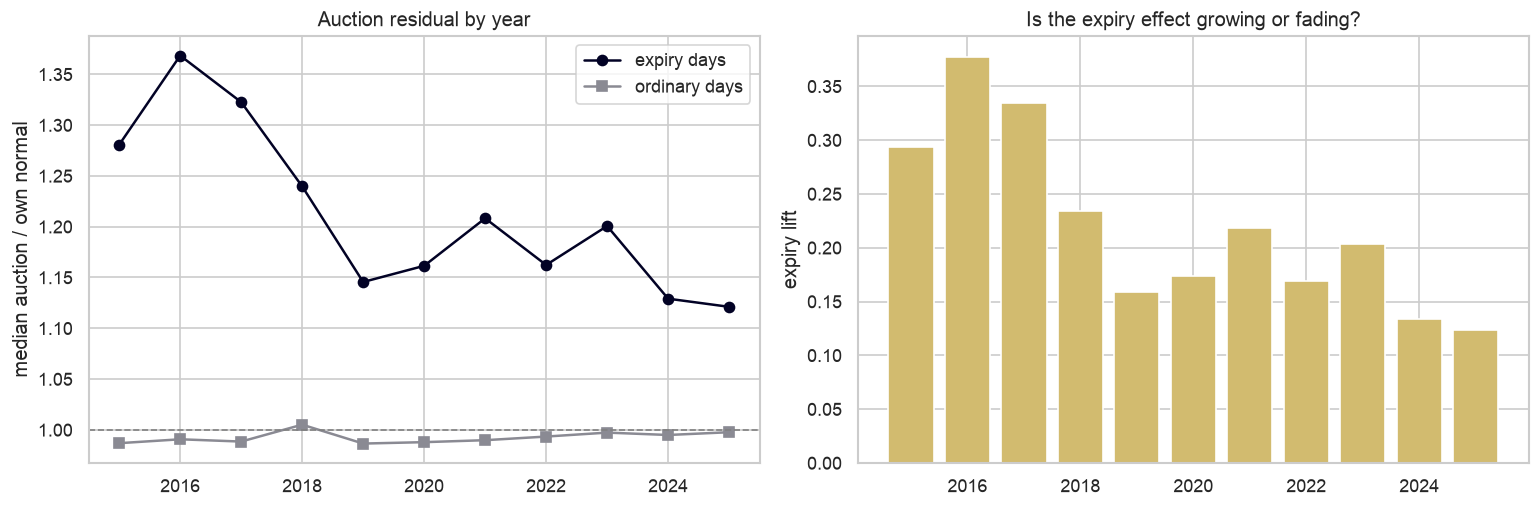

  * Mean expiry lift 2015-2019: 0.2798
  * Mean expiry lift 2021-2025: 0.1696


,year,n,expiring,not_expiring,quarterly_expiry,lift
0,2015,314571,1.2807,0.9869,6.6147,0.2938
1,2016,312982,1.3684,0.9907,5.5032,0.3777
2,2017,303762,1.3226,0.9885,6.7093,0.3341
3,2018,298419,1.2397,1.0051,6.2919,0.2345
4,2019,293519,1.1456,0.9865,5.8571,0.1590
5,2020,288301,1.1615,0.9879,6.2802,0.1736
6,2021,302677,1.2082,0.9898,7.6612,0.2184
7,2022,315409,1.1623,0.9934,7.3124,0.1689
8,2023,308952,1.2007,0.9973,7.2128,0.2034
9,2024,304952,1.1291,0.9950,6.9345,0.1342


In [35]:
over_time = sql(f"""
SELECT year,
       count(*) AS n,
       median(CASE WHEN oi_exp_today > 0 THEN auction_vs_normal END) AS expiring,
       median(CASE WHEN oi_exp_today = 0 THEN auction_vs_normal END) AS not_expiring,
       median(CASE WHEN quarterly_options_expiry THEN auction_vs_normal END) AS quarterly_expiry
FROM read_parquet('{JOINT}')
WHERE {KEEP}
GROUP BY 1 ORDER BY 1
""")
over_time["lift"] = over_time["expiring"] - over_time["not_expiring"]
over_time.to_csv(OUT / "expiry_effect_over_time.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(over_time["year"], over_time["expiring"], marker="o", color=NAVY, label="expiry days")
axes[0].plot(over_time["year"], over_time["not_expiring"], marker="s", color=GREY, label="ordinary days")
axes[0].axhline(1.0, color="grey", ls="--", lw=1)
axes[0].set_ylabel("median auction / own normal")
axes[0].set_title("Auction residual by year")
axes[0].legend()

axes[1].bar(over_time["year"], over_time["lift"], color=GOLD)
axes[1].axhline(0, color="grey", lw=1)
axes[1].set_ylabel("expiry lift")
axes[1].set_title("Is the expiry effect growing or fading?")
fig.tight_layout()
fig.savefig(OUT / "expiry_effect_over_time.png", bbox_inches="tight")
plt.show()

note("Mean expiry lift 2015-2019", round(float(over_time[over_time.year <= 2019]["lift"].mean()), 4))
note("Mean expiry lift 2021-2025", round(float(over_time[over_time.year >= 2021]["lift"].mean()), 4))
over_time

# Part G — Does any of it add value?

Everything so far describes behaviour. These last sections ask the harder question: is any of it
*new*, given the 99 features the panel already carries?

## 21. Ranking every signal, and checking it holds up year by year

Spearman correlations against `log_auction_residual`, on properly lagged columns, plus a per-year
breakdown. A signal that changes sign across years is noise no matter how strong it looks pooled.

,signal,spearman,n
0,oi_exp_today_share,0.1084,3234397
1,oi_exp_today,0.1066,3238205
2,opt_vol_surprise,0.0754,3222927
3,lag1_opt_total_vol,0.0420,3237416
4,lag1_opt_to_stock_vol,0.0223,3237397
5,lag1_pc_vol_ratio,0.0198,2696317
6,oi_exp_7d_share,0.0188,3234397
7,iv_change_20d,0.0186,3094599
8,oi_exp_7d,0.0172,3238205
9,abs_gex_dollar,0.0128,3237388


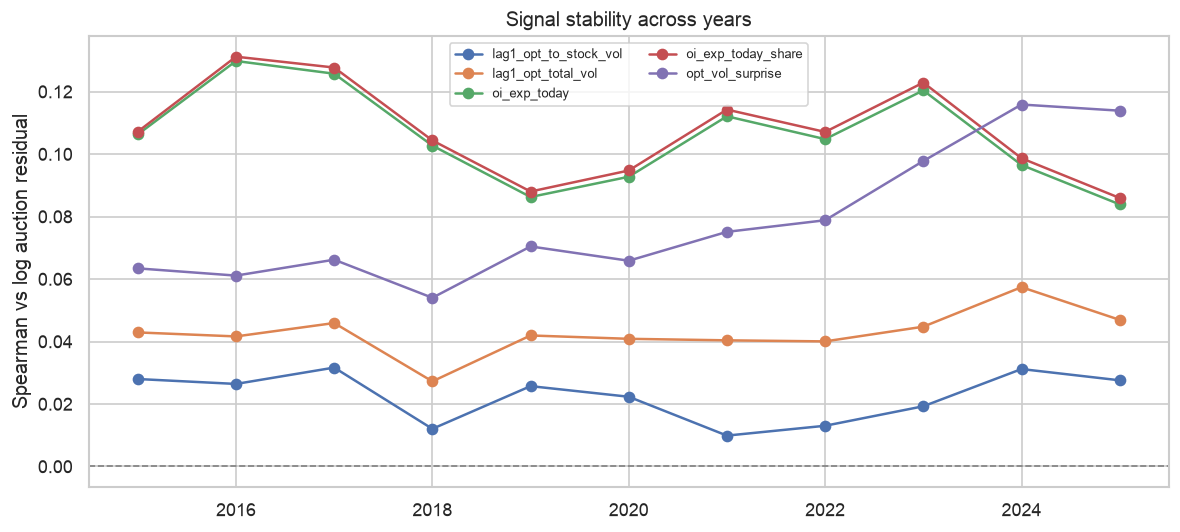

  * Strongest options signal: oi_exp_today_share (rho=0.108)
  * Top-5 signals that flip sign across years: 0


In [36]:
SIGNALS = ["oi_exp_today_share", "oi_exp_today", "oi_exp_7d_share", "oi_exp_7d",
           "opt_vol_surprise", "lag1_opt_to_stock_vol", "lag1_opt_total_vol",
           "lag1_iv_atm_30d", "iv_change_20d", "abs_gex_dollar", "lag1_gex_dollar",
           "lag1_pc_vol_ratio", "pc_oi_ratio", "opt_total_oi", "lag1_n_contracts"]

rows = []
for s in SIGNALS:
    r = sql(f"""
        SELECT corr(a, b) AS rho, count(*) AS n FROM (
            SELECT rank() OVER (ORDER BY log_auction_residual) AS a,
                   rank() OVER (ORDER BY {s}) AS b
            FROM read_parquet('{JOINT}')
            WHERE {KEEP} AND log_auction_residual IS NOT NULL
              AND {s} IS NOT NULL AND isfinite({s})
        )
    """)
    rows.append({"signal": s, "spearman": r["rho"][0], "n": int(r["n"][0])})

signal_table = (pd.DataFrame(rows)
                .sort_values("spearman", key=abs, ascending=False)
                .reset_index(drop=True))
signal_table.to_csv(OUT / "signal_rank_correlations.csv", index=False)
display(signal_table)

top = signal_table["signal"].head(5).tolist()
yearly = []
for s in top:
    r = sql(f"""
        SELECT year, corr(a, b) AS rho FROM (
            SELECT year,
                   rank() OVER (PARTITION BY year ORDER BY log_auction_residual) AS a,
                   rank() OVER (PARTITION BY year ORDER BY {s}) AS b
            FROM read_parquet('{JOINT}')
            WHERE {KEEP} AND log_auction_residual IS NOT NULL
              AND {s} IS NOT NULL AND isfinite({s})
        ) GROUP BY year ORDER BY year
    """)
    r["signal"] = s
    yearly.append(r)
yearly = pd.concat(yearly)
yearly.to_csv(OUT / "signal_stability_by_year.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.6))
for s, grp in yearly.groupby("signal"):
    ax.plot(grp["year"], grp["rho"], marker="o", label=s)
ax.axhline(0, color="grey", ls="--", lw=1)
ax.set_ylabel("Spearman vs log auction residual")
ax.set_title("Signal stability across years")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(OUT / "signal_stability.png", bbox_inches="tight")
plt.show()

note("Strongest options signal",
     f"{signal_table['signal'][0]} (rho={signal_table['spearman'][0]:.3f})")

flips = yearly.groupby("signal")["rho"].apply(lambda s: s.min() * s.max() < 0)
note("Top-5 signals that flip sign across years", int(flips.sum()))

## 22. Does it survive the panel's own features?

Options activity tracks liquidity, and the panel already carries sixteen liquidity features. A signal
that merely restates "this is a heavily traded stock" adds nothing. The check: recompute each
correlation **within** liquidity deciles. Retention near 100% means genuinely new information;
retention near zero means the panel already had it.

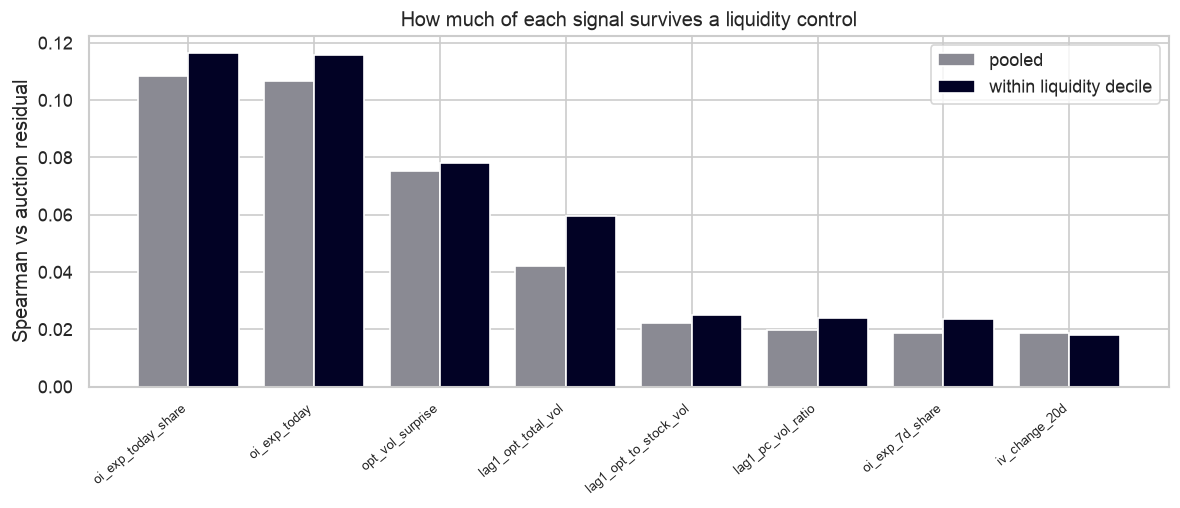

,signal,mean_within_decile,min_decile,max_decile,pooled,retained_pct
6,oi_exp_today_share,0.1165,0.0911,0.1354,0.1084,107.4396
5,oi_exp_today,0.1158,0.0892,0.1350,0.1066,108.6690
7,opt_vol_surprise,0.0780,0.0367,0.1123,0.0754,103.4212
2,lag1_opt_total_vol,0.0595,0.0342,0.0724,0.0420,141.7397
1,lag1_opt_to_stock_vol,0.0250,0.0151,0.0296,0.0223,112.2723
3,lag1_pc_vol_ratio,0.0240,0.0099,0.0384,0.0198,121.0492
4,oi_exp_7d_share,0.0235,0.0132,0.0483,0.0188,124.5850
0,iv_change_20d,0.0181,0.0032,0.0401,0.0186,97.4221


In [37]:
rows = []
for s in signal_table["signal"].head(8):
    r = sql(f"""
        SELECT liquidity_decile, corr(a, b) AS rho, count(*) AS n FROM (
            SELECT liquidity_decile,
                   rank() OVER (PARTITION BY liquidity_decile ORDER BY log_auction_residual) AS a,
                   rank() OVER (PARTITION BY liquidity_decile ORDER BY {s}) AS b
            FROM read_parquet('{JOINT}')
            WHERE {KEEP} AND log_auction_residual IS NOT NULL
              AND {s} IS NOT NULL AND isfinite({s}) AND liquidity_decile IS NOT NULL
        ) GROUP BY liquidity_decile ORDER BY liquidity_decile
    """)
    r["signal"] = s
    rows.append(r)
within_liq = pd.concat(rows)
within_liq.to_csv(OUT / "signal_within_liquidity_deciles.csv", index=False)

retention = (within_liq.groupby("signal")["rho"]
             .agg(mean_within_decile="mean", min_decile="min", max_decile="max")
             .reset_index()
             .merge(signal_table[["signal", "spearman"]], on="signal")
             .rename(columns={"spearman": "pooled"}))
retention["retained_pct"] = 100 * retention["mean_within_decile"] / retention["pooled"]
retention = retention.sort_values("mean_within_decile", key=abs, ascending=False)
retention.to_csv(OUT / "signal_retention_vs_liquidity.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(retention))
ax.bar(x - .2, retention["pooled"], width=.4, color=GREY, label="pooled")
ax.bar(x + .2, retention["mean_within_decile"], width=.4, color=NAVY, label="within liquidity decile")
ax.set_xticks(x)
ax.set_xticklabels(retention["signal"], rotation=40, ha="right", fontsize=8)
ax.axhline(0, color="grey", lw=1)
ax.set_ylabel("Spearman vs auction residual")
ax.set_title("How much of each signal survives a liquidity control")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "signal_retention_vs_liquidity.png", bbox_inches="tight")
plt.show()
retention

## 23. The real test — does a model get better?

Correlations can mislead once features compete. This fits the project's own ridge on the project's
own target definition (`log(auction / 20-day median)`), twice: once on a baseline drawn from panel
features already available, once on the same baseline plus the options block. Same rows, same folds,
same penalty — the only difference is the options columns.

Expanding out-of-time, mirroring notebook 07: for each test year, train on the five preceding years
with a 350,000-row sample. 2025 is excluded because options stop in August.

A WAPE improvement under roughly half a percent is not worth the extra data dependency.

In [38]:
from modeling_utils import fit_preprocessor, apply_preprocessor, fit_ridge, predict_ridge, forecast_metrics

BASE_CONT = ["lag1_auction_volume", "avg20_auction_volume", "avg60_auction_volume",
             "median20_auction_volume", "std20_auction_volume", "auction_cv20",
             "lag1_auction_share", "avg20_auction_share", "lag1_auction_to_adv20",
             "avg20_daily_volume", "lag1_daily_volume", "abnormal_volume_lag1",
             "avg20_turnover", "lag1_amihud", "volatility20", "momentum20",
             "lag1_market_cap", "size_percentile", "liquidity_percentile",
             "trading_days_to_month_end"]
BASE_BOOL = ["monthly_options_expiry", "quarterly_options_expiry", "is_last_5_trading_days_month"]

OPT_CONT = ["opt_total_oi", "pc_oi_ratio", "oi_exp_today", "oi_exp_today_share",
            "oi_exp_7d", "oi_exp_7d_share", "lag1_opt_total_vol", "lag1_opt_to_stock_vol",
            "opt_vol_surprise", "lag1_pc_vol_ratio", "lag1_iv_atm_30d", "iv_change_20d",
            "lag1_gex_dollar", "abs_gex_dollar", "lag1_n_contracts"]
OPT_BOOL = ["has_options"]

NEEDED = sorted(set(BASE_CONT + BASE_BOOL + OPT_CONT + OPT_BOOL
                    + ["auction_volume", "median20_auction_volume", "year"]))
COLS = ", ".join(NEEDED)
LAMBDA = 1e-4

def load(years, limit=None):
    yrs = ", ".join(str(y) for y in years)
    q = f"""SELECT {COLS} FROM read_parquet('{JOINT}')
            WHERE {KEEP} AND year IN ({yrs}) AND auction_volume > 0"""
    if limit:
        q += f" USING SAMPLE {limit} ROWS"
    return sql(q)

results = []
for test_year in [2022, 2023, 2024]:
    train = load(range(test_year - 5, test_year), limit=350_000)
    test = load([test_year])

    y_train = np.log(train["auction_volume"] / train["median20_auction_volume"]).to_numpy()
    offset = np.log(test["median20_auction_volume"].to_numpy())

    for name, cont, boolean in [("baseline", BASE_CONT, BASE_BOOL),
                                ("baseline + options", BASE_CONT + OPT_CONT, BASE_BOOL + OPT_BOOL)]:
        xtr, params = fit_preprocessor(train, cont, boolean, [])
        coef = fit_ridge(xtr, y_train, LAMBDA)
        xte = apply_preprocessor(test, params, cont, boolean, [])
        pred_raw = np.exp(predict_ridge(xte, coef) + offset)
        m = forecast_metrics(test["auction_volume"].to_numpy(), pred_raw)
        m.update({"test_year": test_year, "model": name, "features": xtr.shape[1]})
        results.append(m)
    print(f"  {test_year} done ({len(train):,} train / {len(test):,} test rows)")

ridge = pd.DataFrame(results)[
    ["test_year", "model", "features", "observations", "wape", "mae_log", "rmse_log",
     "spearman", "aggregate_bias"]]
ridge.to_csv(OUT / "incremental_ridge_test.csv", index=False)
display(ridge)

delta = (ridge.pivot(index="test_year", columns="model", values="wape")
         .assign(improvement_pct=lambda d:
                 100 * (d["baseline"] - d["baseline + options"]) / d["baseline"]))
delta.to_csv(OUT / "incremental_ridge_improvement.csv")
note("Mean WAPE improvement from options (%)", round(float(delta["improvement_pct"].mean()), 3))
delta

  2022 done (148,942 train / 315,409 test rows)
  2023 done (150,631 train / 308,952 test rows)
  2024 done (151,657 train / 304,952 test rows)


,test_year,model,features,observations,wape,mae_log,rmse_log,spearman,aggregate_bias
0,2022,baseline,31,315409,0.4025,0.3808,0.5491,0.9361,-0.1534
1,2022,baseline + options,59,315409,0.4028,0.3806,0.5492,0.9360,-0.1551
2,2023,baseline,31,308952,0.3847,0.3500,0.5016,0.9460,-0.1517
3,2023,baseline + options,59,308952,0.3840,0.3497,0.5015,0.9460,-0.1562
4,2024,baseline,31,304952,0.3631,0.3243,0.4623,0.9496,-0.1399
5,2024,baseline + options,59,304952,0.3627,0.3239,0.4620,0.9496,-0.1459


  * Mean WAPE improvement from options (%): 0.068


model,baseline,baseline + options,improvement_pct
test_year,,,
2022,0.4025,0.4028,-0.0840
2023,0.3847,0.3840,0.1810
2024,0.3631,0.3627,0.1072


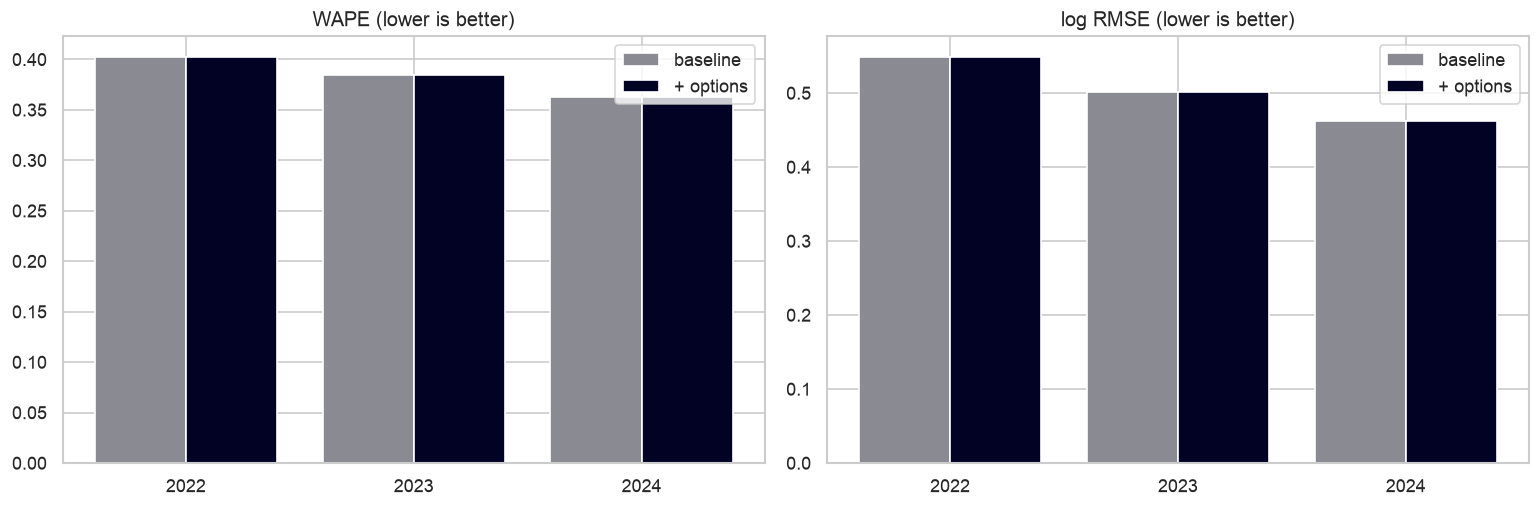

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
piv_w = ridge.pivot(index="test_year", columns="model", values="wape")
piv_r = ridge.pivot(index="test_year", columns="model", values="rmse_log")
for ax, piv, title in [(axes[0], piv_w, "WAPE"), (axes[1], piv_r, "log RMSE")]:
    x = np.arange(len(piv))
    ax.bar(x - .2, piv["baseline"], width=.4, color=GREY, label="baseline")
    ax.bar(x + .2, piv["baseline + options"], width=.4, color=NAVY, label="+ options")
    ax.set_xticks(x); ax.set_xticklabels(piv.index)
    ax.set_title(f"{title} (lower is better)")
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / "incremental_ridge_test.png", bbox_inches="tight")
plt.show()

## 24. Findings

Numbers collected as the notebook ran. How to read the whole thing:

**Does the mechanism exist?** Sections 7–10. The calendar contrast and the event study should agree,
and the dose-response curve in 10 should rise. If it is flat, expiry is a binary event and magnitude
is noise.

**Is it new?** Sections 11 and 22, and they must both hold. Section 11 asks whether magnitude beats
the panel's existing `monthly_options_expiry` flag; section 22 asks whether any signal survives a
liquidity control. A signal that fails either is already in the panel under a different name.

**Is it stable?** Section 20. Options markets changed completely after 2020 — an effect confined to
one half of the sample will not generalise.

**Does it pay?** Section 23 is the only section that answers this directly. Treat a WAPE improvement
under about half a percent as not worth the extra data dependency, given the cost: options coverage
ends 2025-08, and ~5% of stock-days have no options at all.

**If it pays**, the integration is to add the surviving columns to notebook 05 as a new feature group
with the lag rules from section 1, re-run 05, then re-test against
`outputs/eda/09_global_finalists/frozen_global_benchmark.json` on its own folds. Keep only the
signals that passed sections 11, 20, 22 and 23 — the correlation matrix in section 4 shows which are
duplicates of one another.

In [40]:
findings = pd.DataFrame(FINDINGS)
findings.to_csv(OUT / "options_auction_findings.csv", index=False)

artifacts = sorted(p.name for p in OUT.iterdir() if p.suffix in {".csv", ".png", ".parquet"})
print(f"{len(artifacts)} artifacts in {OUT}\n")
for a in artifacts:
    print("   ", a)
print()
findings

58 artifacts in /Users/ravijl/Downloads/blackrock_auction_vol-main/outputs/eda/14_options_auction

    auction_by_options_intensity.csv
    auction_by_options_intensity.png
    case_study_series.png
    case_study_summary.csv
    channel_dealer_gamma.csv
    channel_dealer_gamma.png
    channel_implied_vol.csv
    channel_implied_vol.png
    channel_option_volume.csv
    channel_option_volume.png
    channel_put_call.csv
    channel_put_call.png
    effect_by_sector.csv
    effect_by_size_and_sector.png
    effect_by_size_decile.csv
    effect_within_expiry_flag.csv
    effect_within_expiry_flag.png
    expiry_anticipation_deciles.csv
    expiry_calendar_contrast.csv
    expiry_calendar_contrast.png
    expiry_dose_response.csv
    expiry_dose_response.png
    expiry_effect_over_time.csv
    expiry_effect_over_time.png
    expiry_event_study.csv
    expiry_event_study.png
    expiry_pressure_deciles.csv
    expiry_x_month_end.csv
    expiry_x_month_end.png
    incremental_ridge_improve

,finding,value
0,Joint table rows,"3,488,919"
1,Median join rate 2015-2024 (%),100.0000
2,Median has-options rate 2015-2024 (%),95.3700
3,Options pairs with |rho| > 0.9,6
4,Optionable share of eligible stock-days (%),95.4700
5,"Auction lift, busiest expiry type vs none (x)",6.5690
6,Anticipation spread on non-expiry days (D10-D1),0.0087
7,Dose-response spread (D10-D1),0.4973
8,Spread within expiry days (Q5-Q1),0.0579
9,Mean expiry lift 2015-2019,0.2798
